# 51 — Cross-Gene Biological Findings & Novel Discoveries

Cross-gene pattern analysis of GIN integration decisions. What biological
properties make genes integrate well (or poorly) across species?

**Goal**: Move beyond per-gene alpha to cross-gene patterns that reveal
WHY gene-level integration info works the way it does.

**Key analyses**:
1. Gene archetypes via GIN hidden-space clustering
2. Identity-expression discordance landscape (where alpha adds value beyond prior)
3. ESM-2 structural properties that predict expression conservation
4. Feature-driven gene groups: what drives positive vs negative delta-alpha
5. Cross-species expression validation of top findings
6. Confound control: GIN correction vs technical artifacts
7. Novel biological findings summary

In [1]:
import sys, os, warnings
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning, module="scvi")
sys.path.insert(0, os.path.abspath(".."))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from matplotlib.patches import Patch
import seaborn as sns
import anndata as ad
import torch
import scipy.sparse as sp_mod
from pathlib import Path
from scipy.stats import spearmanr, pearsonr, mannwhitneyu, kruskal
from scipy.cluster.hierarchy import linkage, fcluster, dendrogram
from scipy.spatial.distance import pdist, squareform
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA
from sklearn.linear_model import LinearRegression

from chimera._model import ChimeraModel

plt.rcParams.update({"figure.dpi": 120, "font.size": 10})
REPO = Path("..").resolve()

In [2]:
# === Load model and data ===
ADATA_PATH = REPO / "data" / "processed" / "camex_human_monkey.h5ad"
RUN_DIR = REPO / "training" / "runs" / "iter31-mmd1k-masked-detached"
ORTHOLOG_PATH = REPO / "data" / "processed" / "ortholog_table.csv"

adata = ad.read_h5ad(ADATA_PATH)
ChimeraModel.setup_anndata(adata, species_key="species", batch_key="batch")
model = ChimeraModel.load(str(RUN_DIR / "model"), adata=adata)
model.module.eval()

gin = model.module.gin
W1 = gin.correction_mlp[0].weight.detach().cpu().numpy()
b1 = gin.correction_mlp[0].bias.detach().cpu().numpy()
W2 = gin.correction_mlp[2].weight.detach().cpu().numpy()
b2 = gin.correction_mlp[2].bias.detach().cpu().numpy()

X_feat = model.module.gene_features.cpu().numpy()
prior = model.module.conservation_prior.cpu().numpy()
alpha = model.get_alpha()
correction = model.get_correction()
delta_alpha = model.get_delta_alpha()
S_g = model.get_S_g()
gene_names = adata.var_names.values
G = len(gene_names)

# Map ortho IDs to human gene symbols
ortho_df = pd.read_csv(ORTHOLOG_PATH)
name_map = dict(zip("ortho_" + ortho_df["ortholog_group_id"].astype(str), ortho_df["hsapiens_gene_name"]))
real_names = np.array([name_map.get(gn, gn) for gn in gene_names])

# Hidden activations
H = np.tanh(X_feat @ W1.T + b1)

# Expression data
X_expr = adata.X.toarray() if sp_mod.issparse(adata.X) else np.array(adata.X)
lib = X_expr.sum(axis=1, keepdims=True).clip(min=1)
cpm = X_expr / lib * 1e4
log_cpm = np.log1p(cpm)
species_arr = adata.obs["species"].values
unique_sp = sorted(adata.obs["species"].unique())
ct_arr = adata.obs["cell_type"].values if "cell_type" in adata.obs else None

SCALAR_NAMES = ["ESM2_intersp_var", "mean_identity",
       "log_mean_expr", "log_expr_var", "frac_nonzero",
       "std_identity", "max_identity", "min_identity"]

print(f"Genes: {G}, Cells: {adata.n_obs}, Species: {unique_sp}")
print(f"Gene name mapping: {sum(1 for n in real_names if not n.startswith('ortho_'))}/{G} mapped")
print(f"Cell types: {sorted(adata.obs['cell_type'].unique()) if ct_arr is not None else 'N/A'}")

INFO     File                                                                                                      
         /Users/kemalinecik/git_nosync/master_chimera/chimera/training/runs/iter31-mmd1k-masked-detached/model/mode
         l.pt already downloaded                                                                                   


Genes: 8430, Cells: 12608, Species: ['Human', 'Monkey']
Gene name mapping: 8430/8430 mapped
Cell types: ['B Plasma cells', 'Cholangio', 'Endothelial', 'Hepatocytes', 'Kupffer cells', 'Macrophages', 'NK NKT and T cells', 'fibroblasts']


In [3]:
# === Build comprehensive gene-level DataFrame ===
# Expression statistics per species
sp_mean_expr = {}
sp_frac_nz = {}
for sp in unique_sp:
    mask = species_arr == sp
    sp_mean_expr[sp] = cpm[mask].mean(axis=0)
    sp_frac_nz[sp] = (cpm[mask] > 0).mean(axis=0)

# Expression divergence between species
log_mean_profiles = {sp: np.log1p(1e4 * (X_expr[species_arr == sp] / lib[species_arr == sp]).mean(axis=0))
                     for sp in unique_sp}
expr_divergence = np.abs(log_mean_profiles[unique_sp[0]] - log_mean_profiles[unique_sp[1]])

gene_df = pd.DataFrame({
    "ortho_id": gene_names,
    "gene_name": real_names,
    "alpha": alpha,
    "prior": prior,
    "delta_alpha": delta_alpha,
    "correction": correction,
    "S_g": S_g,
    "expr_divergence": expr_divergence,
    "mean_expr_sp0": sp_mean_expr[unique_sp[0]],
    "mean_expr_sp1": sp_mean_expr[unique_sp[1]],
    "frac_nz_sp0": sp_frac_nz[unique_sp[0]],
    "frac_nz_sp1": sp_frac_nz[unique_sp[1]],
    "mean_identity": X_feat[:, 65],
    "log_mean_expr_feat": X_feat[:, 66],
    "log_expr_var_feat": X_feat[:, 67],
    "frac_nonzero_feat": X_feat[:, 68],
    "esm2_var": X_feat[:, 64],
})
gene_df.index = real_names  # use human gene symbols as index

print(f"Gene DataFrame: {gene_df.shape}")
gene_df.describe().round(3)

Gene DataFrame: (8430, 17)


,alpha,prior,delta_alpha,correction,S_g,expr_divergence,mean_expr_sp0,mean_expr_sp1,frac_nz_sp0,frac_nz_sp1,mean_identity,log_mean_expr_feat,log_expr_var_feat,frac_nonzero_feat,esm2_var
count,8430.000,8430.000,8430.000,8430.000,8430.000,8430.000,8430.000,8430.000,8430.000,8430.000,8430.000,8430.000,8430.000,8430.000,8430.000
mean,0.783,0.800,-0.017,-0.068,0.012,0.240,1.186,1.186,0.181,0.090,0.010,0.030,0.024,0.041,0.013
std,0.122,0.096,0.051,0.298,0.047,0.330,2.983,4.656,0.214,0.133,0.995,1.016,1.017,1.009,1.002
min,0.135,0.164,-0.206,-0.851,0.000,0.000,0.000,0.000,0.000,0.000,-6.469,-0.603,-0.499,-0.808,-1.541
25%,0.710,0.740,-0.047,-0.283,0.000,0.041,0.055,0.079,0.017,0.008,-0.609,-0.539,-0.470,-0.679,-0.739
50%,0.804,0.811,-0.012,-0.097,0.000,0.123,0.292,0.334,0.092,0.036,0.107,-0.353,-0.369,-0.340,-0.179
75%,0.878,0.874,0.013,0.117,0.004,0.302,1.048,1.057,0.273,0.112,0.746,0.131,0.000,0.376,0.580
max,0.976,0.950,0.151,0.820,1.122,5.118,90.825,317.039,0.992,1.000,2.030,11.821,11.190,5.998,5.547


## 1. Gene Archetypes via GIN Hidden-Space Clustering

Each gene passes through the GIN's hidden layer, producing a 32-dimensional
"integration fingerprint". Clustering these reveals natural gene archetypes —
groups of genes that the GIN treats similarly.

**Hypothesis**: Archetypes will correspond to biologically meaningful categories
(e.g., housekeeping, regulatory, tissue-specific).

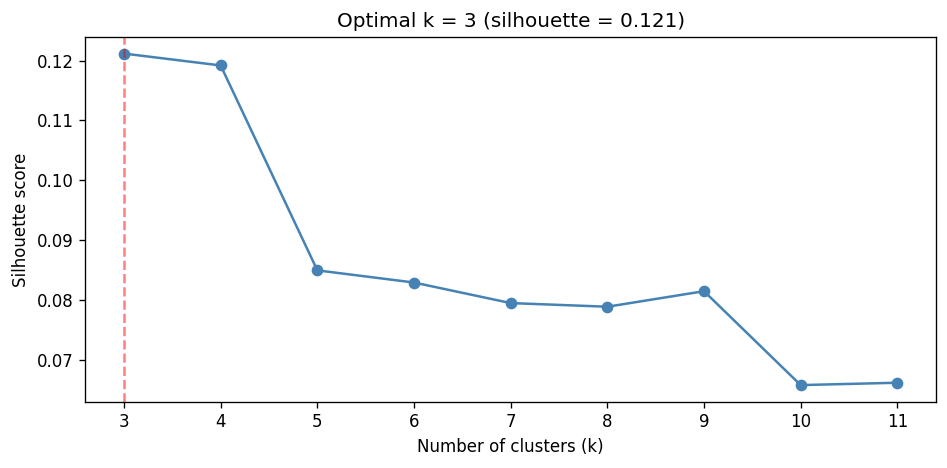


Using k=3 archetypes
archetype
0    3705
1    2909
2    1816
Name: count, dtype: int64


In [4]:
# Determine optimal k via silhouette score
sil_scores = []
K_range = range(3, 12)
for k in K_range:
    km = KMeans(n_clusters=k, n_init=10, random_state=42)
    labels = km.fit_predict(H)
    sil = silhouette_score(H, labels, sample_size=min(5000, G))
    sil_scores.append(sil)

best_k = list(K_range)[np.argmax(sil_scores)]

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(list(K_range), sil_scores, "o-", color="steelblue")
ax.axvline(best_k, color="red", linestyle="--", alpha=0.5)
ax.set_xlabel("Number of clusters (k)")
ax.set_ylabel("Silhouette score")
ax.set_title(f"Optimal k = {best_k} (silhouette = {max(sil_scores):.3f})")
plt.tight_layout()
plt.show()

# Fit final clustering
km_final = KMeans(n_clusters=best_k, n_init=20, random_state=42)
gene_df["archetype"] = km_final.fit_predict(H)
print(f"\nUsing k={best_k} archetypes")
print(gene_df["archetype"].value_counts().sort_index())

In [5]:
# Characterize each archetype
arch_stats = gene_df.groupby("archetype").agg(
    n_genes=("alpha", "count"),
    alpha_mean=("alpha", "mean"),
    alpha_std=("alpha", "std"),
    delta_alpha_mean=("delta_alpha", "mean"),
    correction_mean=("correction", "mean"),
    prior_mean=("prior", "mean"),
    S_g_mean=("S_g", "mean"),
    expr_div_mean=("expr_divergence", "mean"),
    frac_delta_pos=("delta_alpha", lambda x: (x > 0.02).mean()),
    frac_delta_neg=("delta_alpha", lambda x: (x < -0.02).mean()),
).round(3)

print("=== Archetype Characteristics ===")
print(arch_stats.to_string())

# Mean feature profile per archetype (scalar features)
arch_feat_profiles = np.zeros((best_k, 8))
for a in range(best_k):
    mask_a = gene_df["archetype"].values == a
    arch_feat_profiles[a] = X_feat[mask_a, 64:].mean(axis=0)

print("\n=== Mean Scalar Feature Profile per Archetype (StandardScaled) ===")
feat_profile_df = pd.DataFrame(arch_feat_profiles, columns=SCALAR_NAMES,
                                index=[f"Arch {i}" for i in range(best_k)])
print(feat_profile_df.round(2).to_string())

=== Archetype Characteristics ===
           n_genes  alpha_mean  alpha_std  delta_alpha_mean  correction_mean  prior_mean  S_g_mean  expr_div_mean  frac_delta_pos  frac_delta_neg
archetype                                                                                                                                        
0             3705       0.812      0.094            -0.007           -0.044       0.819     0.010          0.249            0.04           0.212
1             2909       0.696      0.125            -0.070           -0.372       0.766     0.004          0.219            0.00           0.974
2             1816       0.862      0.076             0.046            0.367       0.816     0.028          0.258            0.85           0.000

=== Mean Scalar Feature Profile per Archetype (StandardScaled) ===
        ESM2_intersp_var  mean_identity  log_mean_expr  log_expr_var  frac_nonzero  std_identity  max_identity  min_identity
Arch 0             -0.07           0.20    

/var/folders/y7/7c17s0l57szdjc1cdc9dmnpm0000gn/T/ipykernel_23752/4059442927.py:42: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(arch_data, labels=[f"A{i}" for i in range(best_k)], patch_artist=True)
/var/folders/y7/7c17s0l57szdjc1cdc9dmnpm0000gn/T/ipykernel_23752/4059442927.py:51: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(arch_data_da, labels=[f"A{i}" for i in range(best_k)], patch_artist=True)


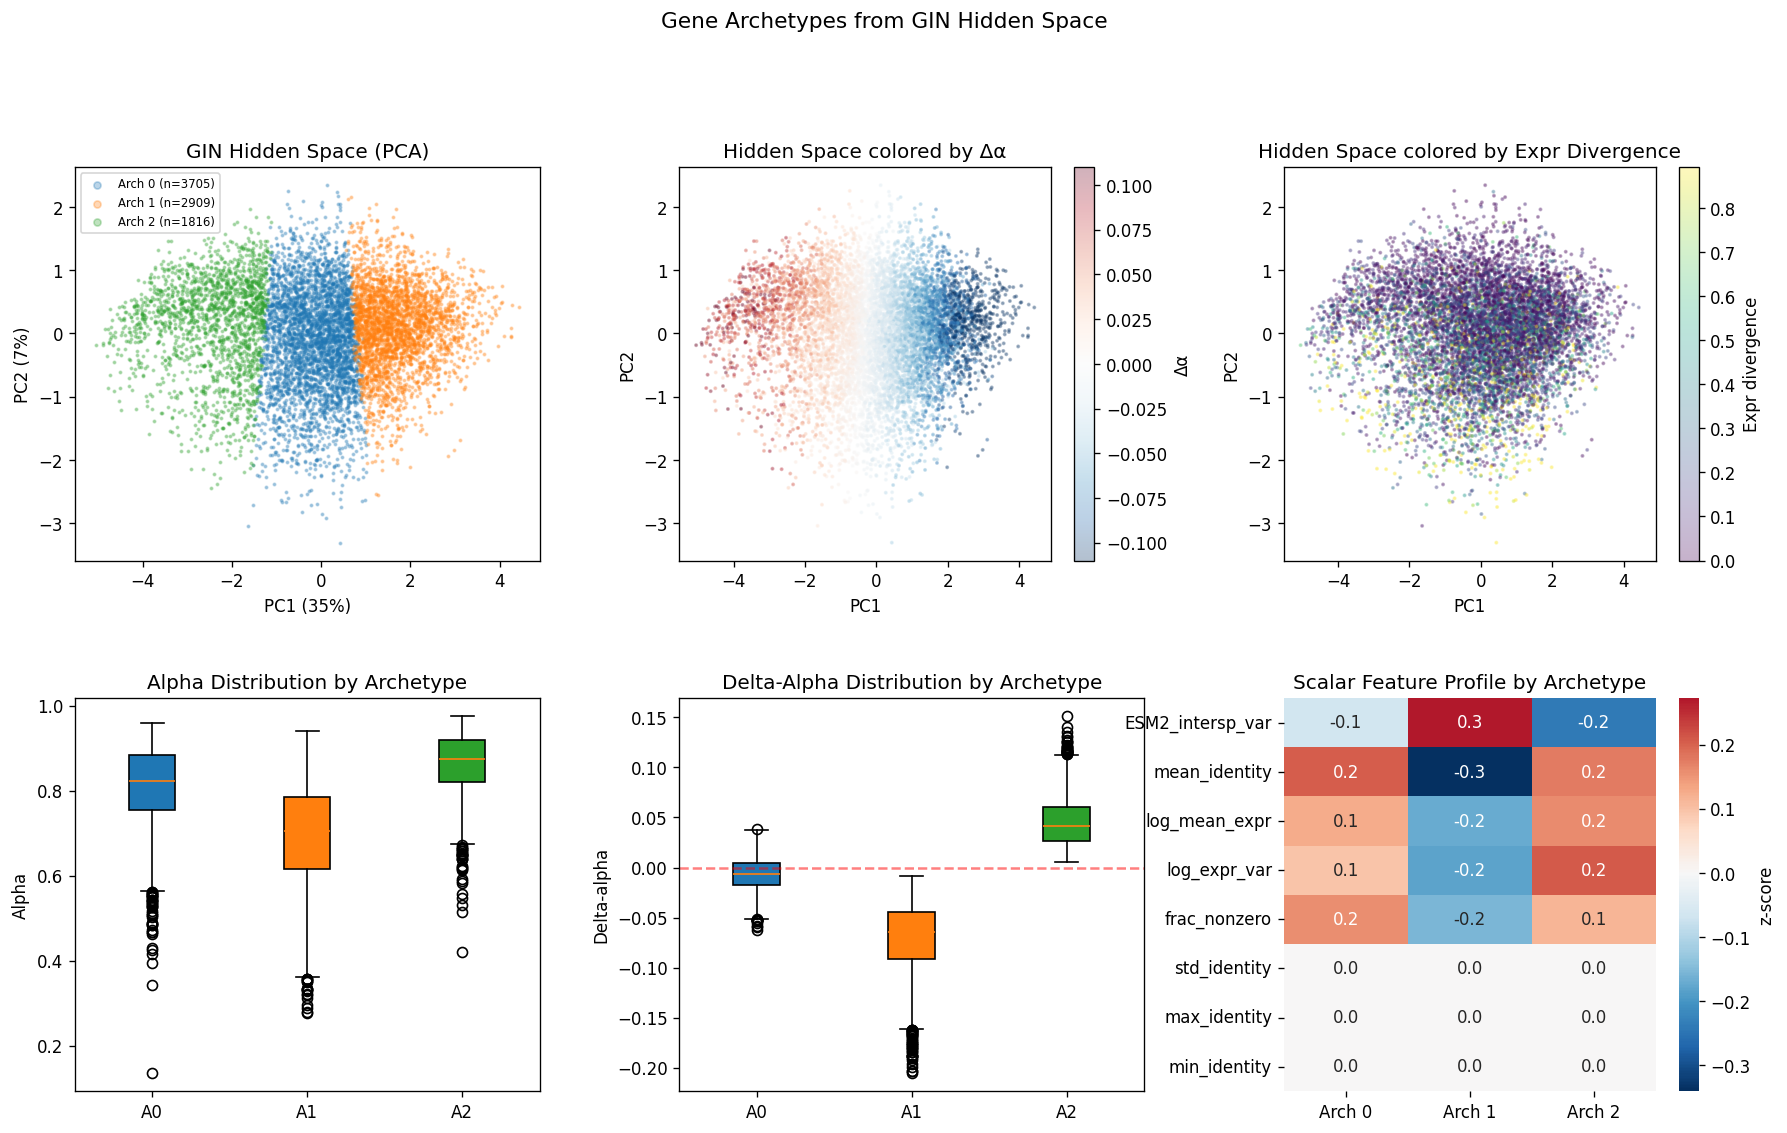


Kruskal-Wallis test (Δα across archetypes): H=6876.4, p=0.00e+00


In [6]:
# Visualize archetypes
# PCA projection of hidden activations for visualization
pca_h = PCA(n_components=2, random_state=42)
H_2d = pca_h.fit_transform(H)

fig = plt.figure(figsize=(18, 10))
gs = gridspec.GridSpec(2, 3, figure=fig, hspace=0.35, wspace=0.3)

# (a) PCA scatter colored by archetype
ax = fig.add_subplot(gs[0, 0])
for a in range(best_k):
    mask_a = gene_df["archetype"].values == a
    ax.scatter(H_2d[mask_a, 0], H_2d[mask_a, 1], s=2, alpha=0.3,
              label=f"Arch {a} (n={mask_a.sum()})")
ax.set_xlabel(f"PC1 ({pca_h.explained_variance_ratio_[0]:.0%})")
ax.set_ylabel(f"PC2 ({pca_h.explained_variance_ratio_[1]:.0%})")
ax.set_title("GIN Hidden Space (PCA)")
ax.legend(fontsize=7, markerscale=3)

# (b) PCA scatter colored by delta-alpha
ax = fig.add_subplot(gs[0, 1])
vmax = np.percentile(np.abs(delta_alpha), 95)
sc = ax.scatter(H_2d[:, 0], H_2d[:, 1], c=delta_alpha, cmap="RdBu_r",
               s=2, alpha=0.3, vmin=-vmax, vmax=vmax)
plt.colorbar(sc, ax=ax, label="Δα")
ax.set_xlabel(f"PC1")
ax.set_ylabel(f"PC2")
ax.set_title("Hidden Space colored by Δα")

# (c) PCA scatter colored by expression divergence
ax = fig.add_subplot(gs[0, 2])
sc = ax.scatter(H_2d[:, 0], H_2d[:, 1], c=expr_divergence, cmap="viridis",
               s=2, alpha=0.3, vmin=0, vmax=np.percentile(expr_divergence, 95))
plt.colorbar(sc, ax=ax, label="Expr divergence")
ax.set_xlabel(f"PC1")
ax.set_ylabel(f"PC2")
ax.set_title("Hidden Space colored by Expr Divergence")

# (d) Archetype box plots: alpha distribution
ax = fig.add_subplot(gs[1, 0])
arch_data = [gene_df[gene_df["archetype"] == a]["alpha"].values for a in range(best_k)]
bp = ax.boxplot(arch_data, labels=[f"A{i}" for i in range(best_k)], patch_artist=True)
for i, patch in enumerate(bp["boxes"]):
    patch.set_facecolor(plt.cm.tab10(i/10))
ax.set_ylabel("Alpha")
ax.set_title("Alpha Distribution by Archetype")

# (e) Archetype box plots: delta-alpha
ax = fig.add_subplot(gs[1, 1])
arch_data_da = [gene_df[gene_df["archetype"] == a]["delta_alpha"].values for a in range(best_k)]
bp = ax.boxplot(arch_data_da, labels=[f"A{i}" for i in range(best_k)], patch_artist=True)
for i, patch in enumerate(bp["boxes"]):
    patch.set_facecolor(plt.cm.tab10(i/10))
ax.axhline(0, color="red", linestyle="--", alpha=0.5)
ax.set_ylabel("Delta-alpha")
ax.set_title("Delta-Alpha Distribution by Archetype")

# (f) Feature radar: scalar features per archetype
ax = fig.add_subplot(gs[1, 2])
sns.heatmap(feat_profile_df.T, annot=True, fmt=".1f", cmap="RdBu_r", center=0,
            ax=ax, cbar_kws={"label": "z-score"})
ax.set_title("Scalar Feature Profile by Archetype")

fig.suptitle("Gene Archetypes from GIN Hidden Space", fontsize=13, y=1.01)
plt.show()

# Kruskal-Wallis test: do archetypes differ in delta-alpha?
stat, p = kruskal(*arch_data_da)
print(f"\nKruskal-Wallis test (Δα across archetypes): H={stat:.1f}, p={p:.2e}")

In [7]:
# Top genes per archetype (with real gene names)
print("=== Representative Genes per Archetype (by |delta_alpha|) ===")
for a in range(best_k):
    arch_genes = gene_df[gene_df["archetype"] == a].copy()
    arch_genes["abs_da"] = arch_genes["delta_alpha"].abs()
    top = arch_genes.nlargest(8, "abs_da")[["gene_name", "alpha", "prior", "delta_alpha", "S_g", "expr_divergence"]]
    print(f"\n--- Archetype {a} ({len(arch_genes)} genes, mean Δα={arch_genes['delta_alpha'].mean():+.4f}) ---")
    print(top.to_string(float_format=lambda x: f"{x:.3f}"))

=== Representative Genes per Archetype (by |delta_alpha|) ===

--- Archetype 0 (3705 genes, mean Δα=-0.0068) ---
         gene_name  alpha  prior  delta_alpha   S_g  expr_divergence
TSPO2        TSPO2  0.602  0.665       -0.063 0.000            0.005
FBXL17      FBXL17  0.666  0.725       -0.059 0.008            0.108
SRD5A1      SRD5A1  0.633  0.691       -0.058 0.022            1.037
KIAA1958  KIAA1958  0.595  0.651       -0.056 0.023            0.185
CCDC137    CCDC137  0.587  0.640       -0.054 0.000            0.136
CRYL1        CRYL1  0.673  0.726       -0.053 0.091            0.442
WBP2NL      WBP2NL  0.533  0.586       -0.053 0.000            0.231
PARP9        PARP9  0.527  0.580       -0.053 0.008            0.239

--- Archetype 1 (2909 genes, mean Δα=-0.0700) ---
         gene_name  alpha  prior  delta_alpha   S_g  expr_divergence
MRNIP        MRNIP  0.331  0.536       -0.206 0.000            0.174
TSSC4        TSSC4  0.407  0.610       -0.203 0.002            0.300
CDKN1C  

## 2. Identity-Expression Discordance Landscape

Plot genes in (sequence identity, expression divergence) space, colored by delta-alpha.

**Critical finding from initial analysis**: Expression *level* (mean, variance, fraction 
expressing) is the dominant driver of delta-alpha (~38% R²), not the identity/divergence 
mismatch directly. High-expression genes are better fit by the shared decoder (FQR signal 
is stronger), so they get pushed above prior regardless of quadrant.

To find the true biological discordance signal, we must **residualize delta-alpha against 
expression statistics** before interpreting quadrants.

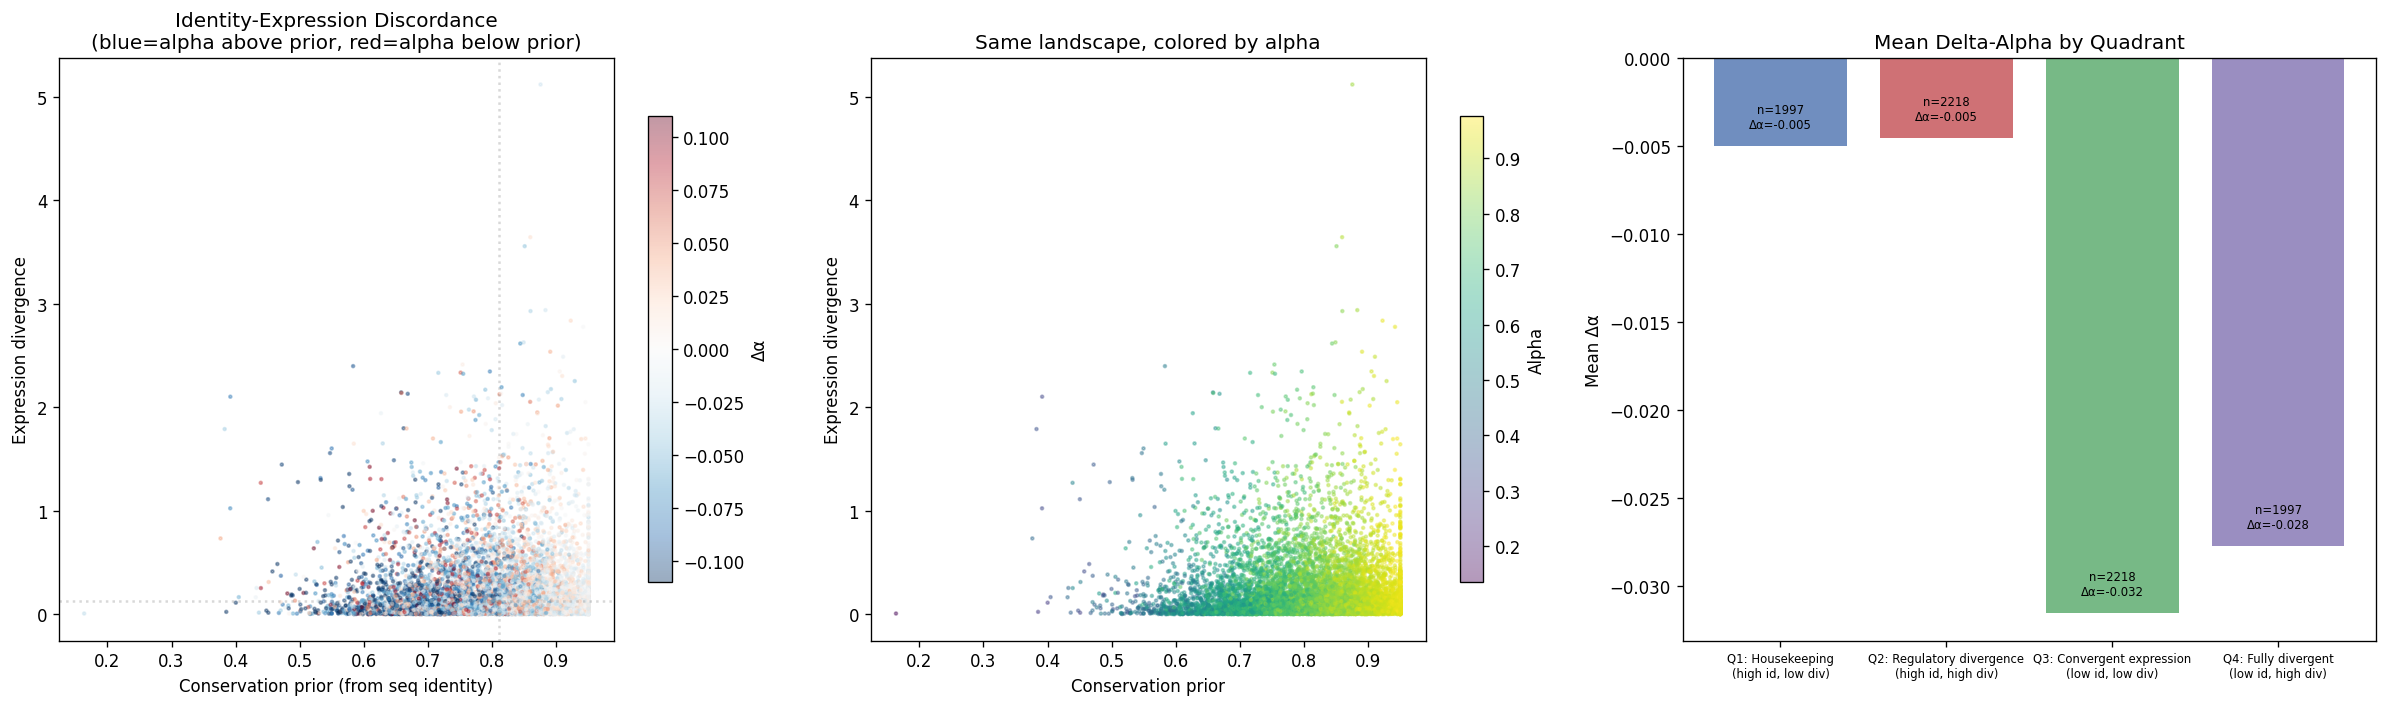

=== Quadrant Analysis ===
  Q1: Housekeeping               n= 1997  mean Δα=-0.0050  std=0.0314  frac Δα>0.02=18.6%  frac Δα<-0.02=29.1%
  Q2: Regulatory divergence      n= 2218  mean Δα=-0.0045  std=0.0308  frac Δα>0.02=18.5%  frac Δα<-0.02=27.5%
  Q3: Convergent expression      n= 2218  mean Δα=-0.0315  std=0.0619  frac Δα>0.02=21.1%  frac Δα<-0.02=58.0%
  Q4: Fully divergent            n= 1997  mean Δα=-0.0277  std=0.0617  frac Δα>0.02=22.1%  frac Δα<-0.02=57.0%


In [8]:
fig, axes = plt.subplots(1, 3, figsize=(20, 6))

# (a) Landscape colored by delta-alpha
ax = axes[0]
vmax = np.percentile(np.abs(delta_alpha), 95)
sc = ax.scatter(prior, expr_divergence, c=delta_alpha, cmap="RdBu_r",
               s=3, alpha=0.4, vmin=-vmax, vmax=vmax, rasterized=True)
plt.colorbar(sc, ax=ax, label="Δα", shrink=0.8)
ax.set_xlabel("Conservation prior (from seq identity)")
ax.set_ylabel("Expression divergence")
ax.set_title("Identity-Expression Discordance\n(blue=alpha above prior, red=alpha below prior)")

# Add quadrant labels
med_prior = np.median(prior)
med_div = np.median(expr_divergence)
ax.axvline(med_prior, color="gray", linestyle=":", alpha=0.3)
ax.axhline(med_div, color="gray", linestyle=":", alpha=0.3)

# (b) Landscape colored by alpha
ax = axes[1]
sc = ax.scatter(prior, expr_divergence, c=alpha, cmap="viridis",
               s=3, alpha=0.4, rasterized=True)
plt.colorbar(sc, ax=ax, label="Alpha", shrink=0.8)
ax.set_xlabel("Conservation prior")
ax.set_ylabel("Expression divergence")
ax.set_title("Same landscape, colored by alpha")

# (c) Quadrant analysis
ax = axes[2]
q1 = (prior > med_prior) & (expr_divergence < med_div)  # conserved-conserved
q2 = (prior > med_prior) & (expr_divergence >= med_div)  # high-id, high-div
q3 = (prior <= med_prior) & (expr_divergence < med_div)  # low-id, low-div
q4 = (prior <= med_prior) & (expr_divergence >= med_div)  # divergent-divergent

quadrants = {"Q1: Housekeeping\n(high id, low div)": q1,
             "Q2: Regulatory divergence\n(high id, high div)": q2,
             "Q3: Convergent expression\n(low id, low div)": q3,
             "Q4: Fully divergent\n(low id, high div)": q4}

q_names = list(quadrants.keys())
q_da_means = [delta_alpha[m].mean() for m in quadrants.values()]
q_counts = [m.sum() for m in quadrants.values()]
q_colors = ["#4C72B0", "#C44E52", "#55A868", "#8172B2"]

bars = ax.bar(range(4), q_da_means, color=q_colors, alpha=0.8)
ax.set_xticks(range(4))
ax.set_xticklabels(q_names, fontsize=7, ha="center")
ax.axhline(0, color="black", linestyle="--", linewidth=0.5)
ax.set_ylabel("Mean Δα")
ax.set_title("Mean Delta-Alpha by Quadrant")
for bar, cnt, val in zip(bars, q_counts, q_da_means):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.001,
            f"n={cnt}\nΔα={val:.3f}", ha="center", fontsize=7)

fig.tight_layout()
plt.show()

# Statistical tests
print("=== Quadrant Analysis ===")
for name, mask in quadrants.items():
    da = delta_alpha[mask]
    print(f"  {name.split(chr(10))[0]:<30} n={mask.sum():5d}  "
          f"mean Δα={da.mean():+.4f}  std={da.std():.4f}  "
          f"frac Δα>0.02={((da>0.02).mean()):.1%}  frac Δα<-0.02={((da<-0.02).mean()):.1%}")

In [9]:
# === Expression-residualized delta-alpha for true biological signal ===
# Remove the expression-level confound to find genes where the GIN learned
# something beyond "highly expressed genes integrate better"
expr_features = X_feat[:, 66:69]  # log_mean_expr, log_expr_var, frac_nonzero
lr_expr_ctrl = LinearRegression().fit(expr_features, delta_alpha)
da_resid = delta_alpha - lr_expr_ctrl.predict(expr_features)
gene_df["da_residualized"] = da_resid

print(f"Expression-level R² on Δα: {lr_expr_ctrl.score(expr_features, delta_alpha):.3f}")
print(f"Raw Δα vs residualized Δα correlation: r={spearmanr(delta_alpha, da_resid).correlation:.3f}")

# Re-analyze quadrants with residualized delta-alpha
print("\n=== Quadrant Analysis: Raw vs Expression-Residualized Δα ===")
print(f"{'Quadrant':<40} {'raw Δα':>10} {'resid Δα':>10} {'n':>6}")
print("-" * 70)
for name, mask in quadrants.items():
    qn = name.split(chr(10))[0]
    print(f"  {qn:<38} {delta_alpha[mask].mean():+10.4f} {da_resid[mask].mean():+10.4f} {mask.sum():6d}")

# Top genes by RESIDUALIZED delta-alpha
print(f"\n{'='*75}")
print("  TOP EXPRESSION-CORRECTED Δα GENES")
print("  (These genes' integration deviates from prior BEYOND the expression effect)")
print(f"{'='*75}")

print(f"\n  Top 15 positive resid Δα (genuinely more conserved than expected):")
print(f"  {'Gene':<15} {'α':>6} {'prior':>6} {'Δα':>8} {'resid Δα':>9} {'expr_div':>9} {'expr_lvl':>9}")
for i in np.argsort(-da_resid)[:15]:
    print(f"  {real_names[i]:<15} {alpha[i]:6.3f} {prior[i]:6.3f} {delta_alpha[i]:+8.4f} "
          f"{da_resid[i]:+9.4f} {expr_divergence[i]:9.3f} {X_feat[i,66]:+9.2f}")

print(f"\n  Top 15 negative resid Δα (genuinely more divergent than expected):")
for i in np.argsort(da_resid)[:15]:
    print(f"  {real_names[i]:<15} {alpha[i]:6.3f} {prior[i]:6.3f} {delta_alpha[i]:+8.4f} "
          f"{da_resid[i]:+9.4f} {expr_divergence[i]:9.3f} {X_feat[i,66]:+9.2f}")

# Q2 regulatory divergence candidates (expression-corrected)
print(f"\n--- Q2: Regulatory Divergence (expression-corrected) ---")
q2_resid_genes = [i for i in np.argsort(da_resid) if q2[i]][:10]
for i in q2_resid_genes:
    print(f"  {real_names[i]:<15} α={alpha[i]:.3f} prior={prior[i]:.3f} "
          f"resid_Δα={da_resid[i]:+.4f} expr_div={expr_divergence[i]:.3f}")

# Q3 convergent expression candidates (expression-corrected)
print(f"\n--- Q3: Convergent Expression (expression-corrected) ---")
q3_resid_genes = [i for i in np.argsort(-da_resid) if q3[i]][:10]
for i in q3_resid_genes:
    print(f"  {real_names[i]:<15} α={alpha[i]:.3f} prior={prior[i]:.3f} "
          f"resid_Δα={da_resid[i]:+.4f} expr_div={expr_divergence[i]:.3f}")

Expression-level R² on Δα: 0.025
Raw Δα vs residualized Δα correlation: r=0.983

=== Quadrant Analysis: Raw vs Expression-Residualized Δα ===
Quadrant                                     raw Δα   resid Δα      n
----------------------------------------------------------------------
  Q1: Housekeeping                          -0.0050    +0.0142   1997
  Q2: Regulatory divergence                 -0.0045    +0.0100   2218
  Q3: Convergent expression                 -0.0315    -0.0116   2218
  Q4: Fully divergent                       -0.0277    -0.0124   1997

  TOP EXPRESSION-CORRECTED Δα GENES
  (These genes' integration deviates from prior BEYOND the expression effect)

  Top 15 positive resid Δα (genuinely more conserved than expected):
  Gene                 α  prior       Δα  resid Δα  expr_div  expr_lvl
  IL13RA2          0.758  0.607  +0.1513   +0.1720     0.263     -0.54
  IFNAR1           0.646  0.506  +0.1403   +0.1605     0.205     -0.13
  ADAM28           0.800  0.670  +0.130

## 3. Expression Patterns of Biologically Interesting Genes

Validate the top discordant genes by showing their actual per-species,
per-cell-type expression patterns.

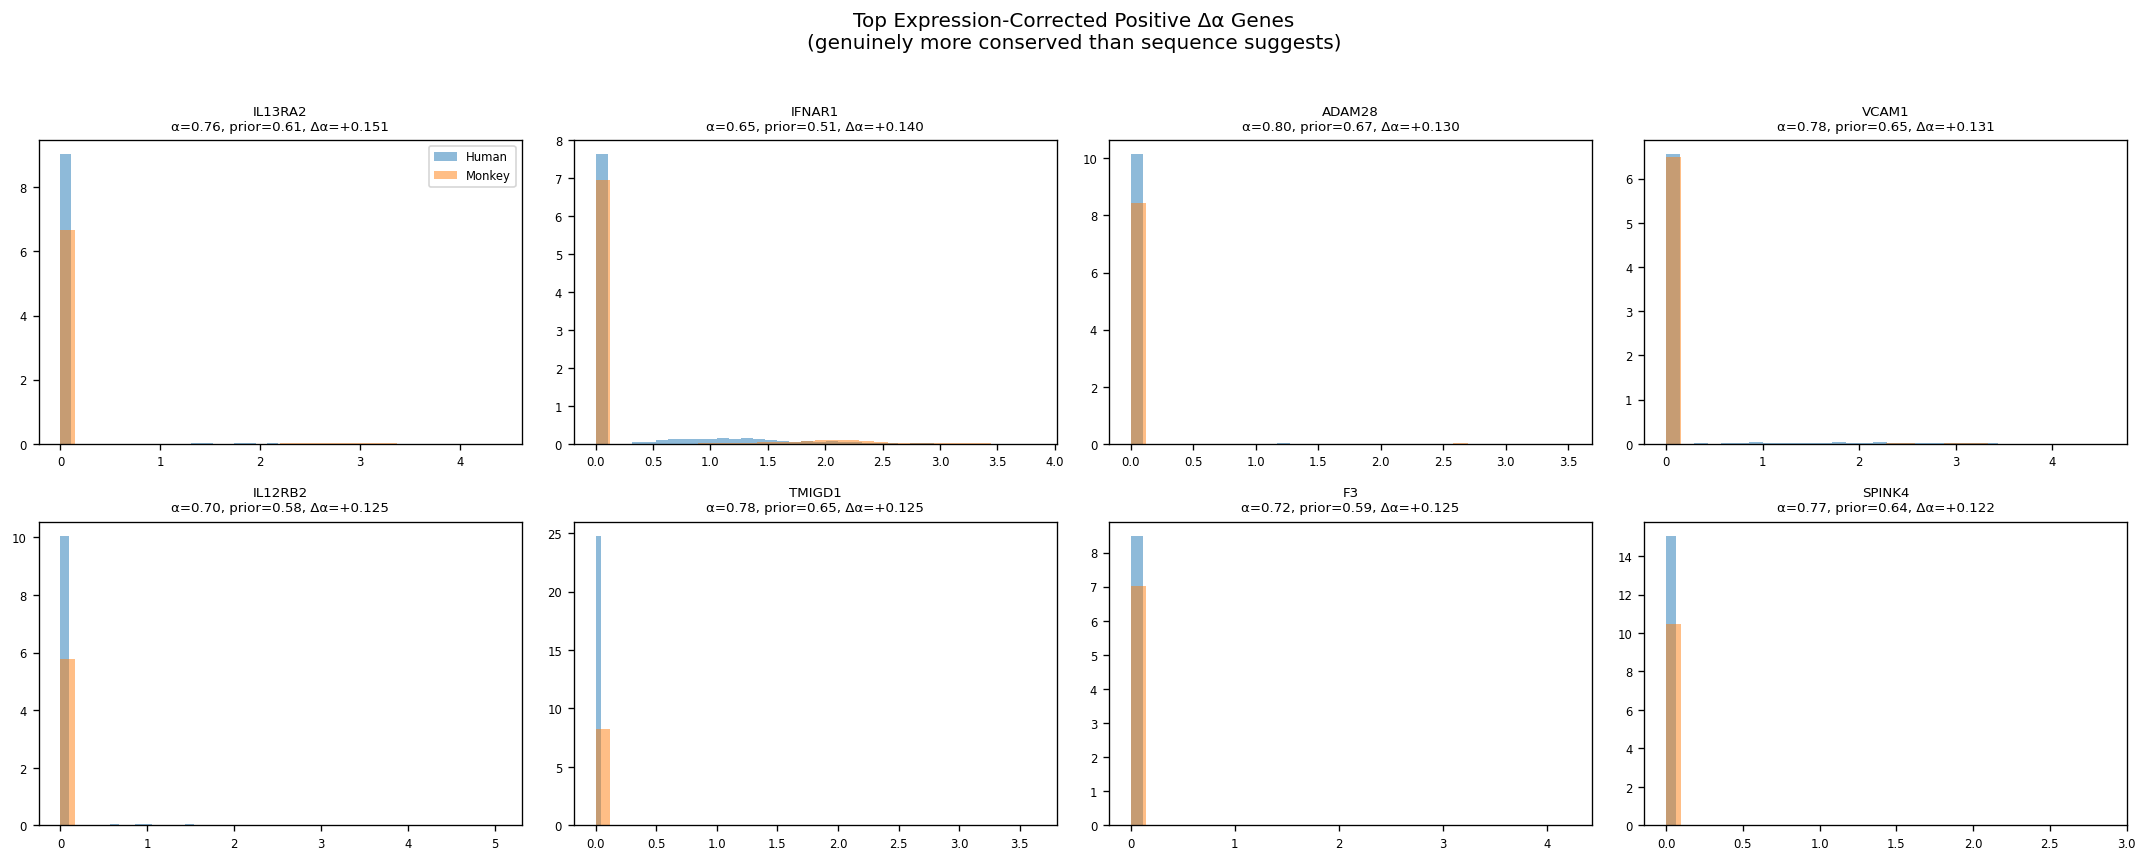

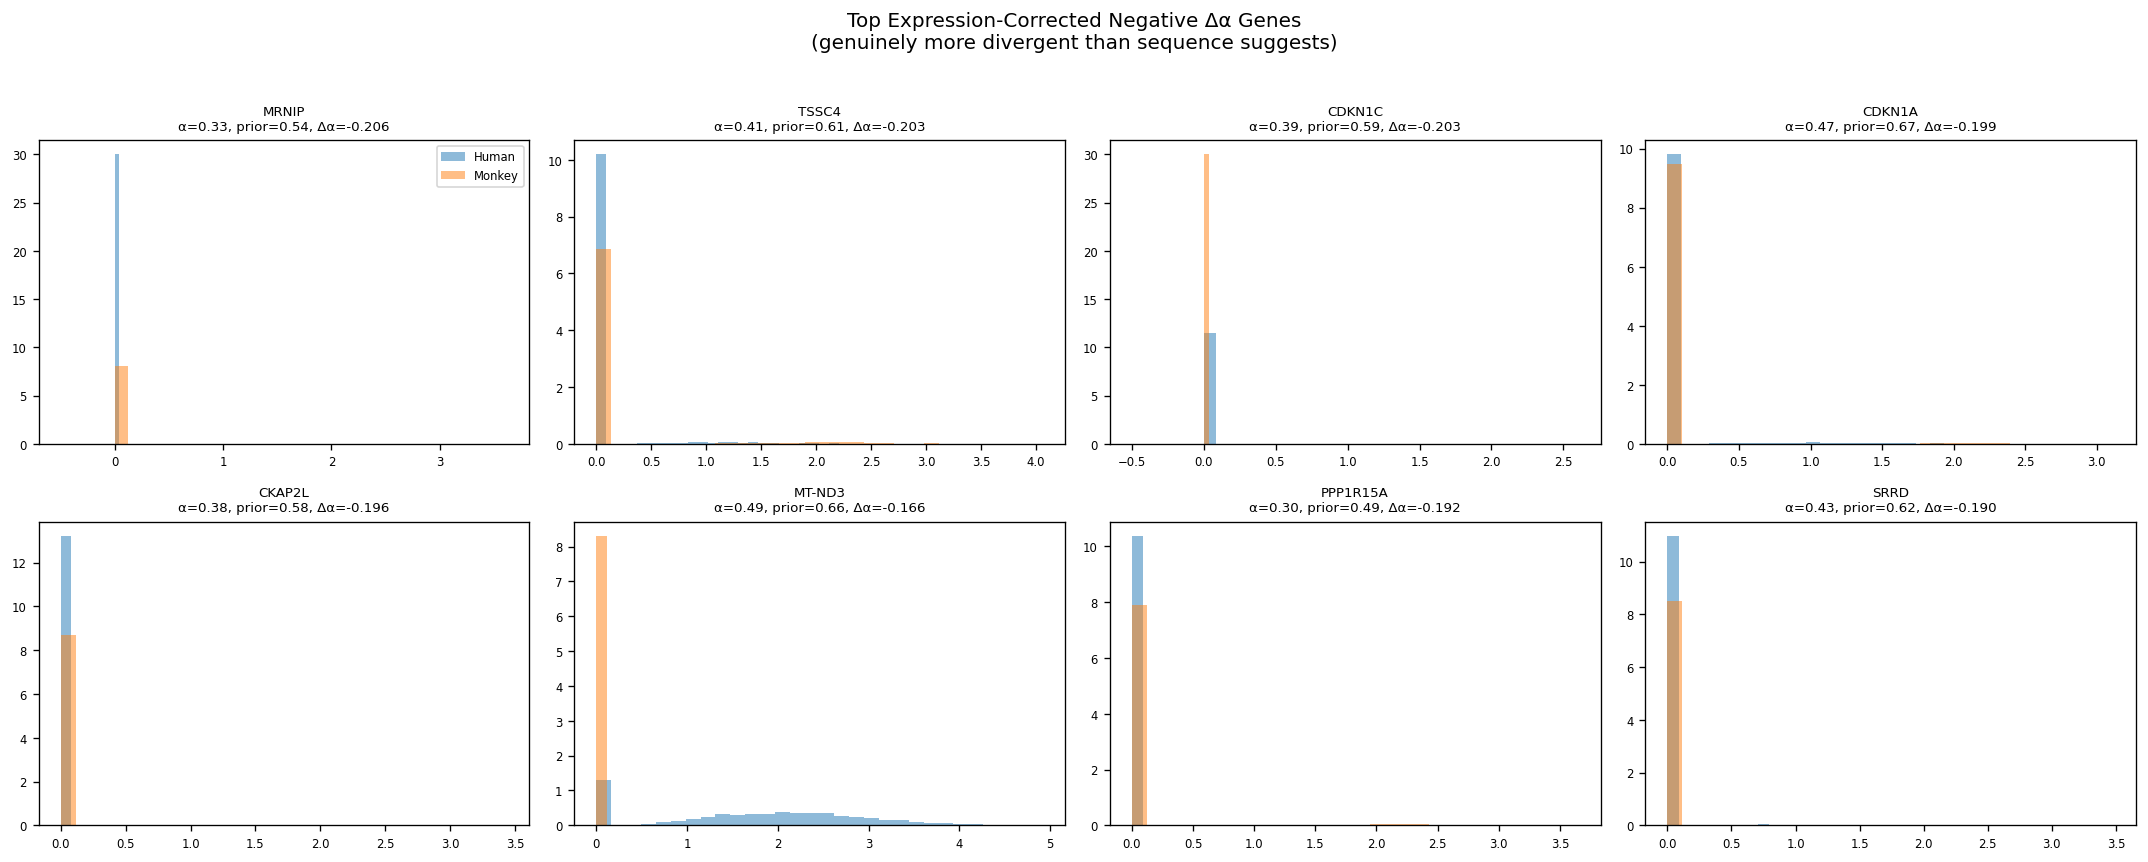

In [10]:
def plot_gene_expression_detail(gene_indices, title, n_show=8):
    """Show per-species expression distribution for genes by index."""
    indices = gene_indices[:n_show]
    n_cols = min(4, len(indices))
    n_rows = (len(indices) + n_cols - 1) // n_cols
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(4.5 * n_cols, 3.5 * n_rows), squeeze=False)
    
    for idx, g_idx in enumerate(indices):
        row, col = idx // n_cols, idx % n_cols
        ax = axes[row, col]
        for sp in unique_sp:
            sp_mask = species_arr == sp
            vals = log_cpm[sp_mask, g_idx]
            ax.hist(vals, bins=30, alpha=0.5, density=True, label=sp, edgecolor="none")
        ax.set_title(f"{real_names[g_idx]}\nα={alpha[g_idx]:.2f}, prior={prior[g_idx]:.2f}, "
                     f"Δα={delta_alpha[g_idx]:+.3f}", fontsize=8)
        ax.tick_params(labelsize=7)
        if idx == 0:
            ax.legend(fontsize=7)
    for idx in range(len(indices), n_rows * n_cols):
        axes[idx // n_cols, idx % n_cols].set_visible(False)
    fig.suptitle(title, fontsize=12, y=1.02)
    fig.tight_layout()
    plt.show()

# Use expression-corrected top genes for more meaningful biology
top_pos_resid = np.argsort(-da_resid)[:8]
top_neg_resid = np.argsort(da_resid)[:8]

plot_gene_expression_detail(
    top_pos_resid,
    "Top Expression-Corrected Positive Δα Genes\n(genuinely more conserved than sequence suggests)"
)
plot_gene_expression_detail(
    top_neg_resid,
    "Top Expression-Corrected Negative Δα Genes\n(genuinely more divergent than sequence suggests)"
)

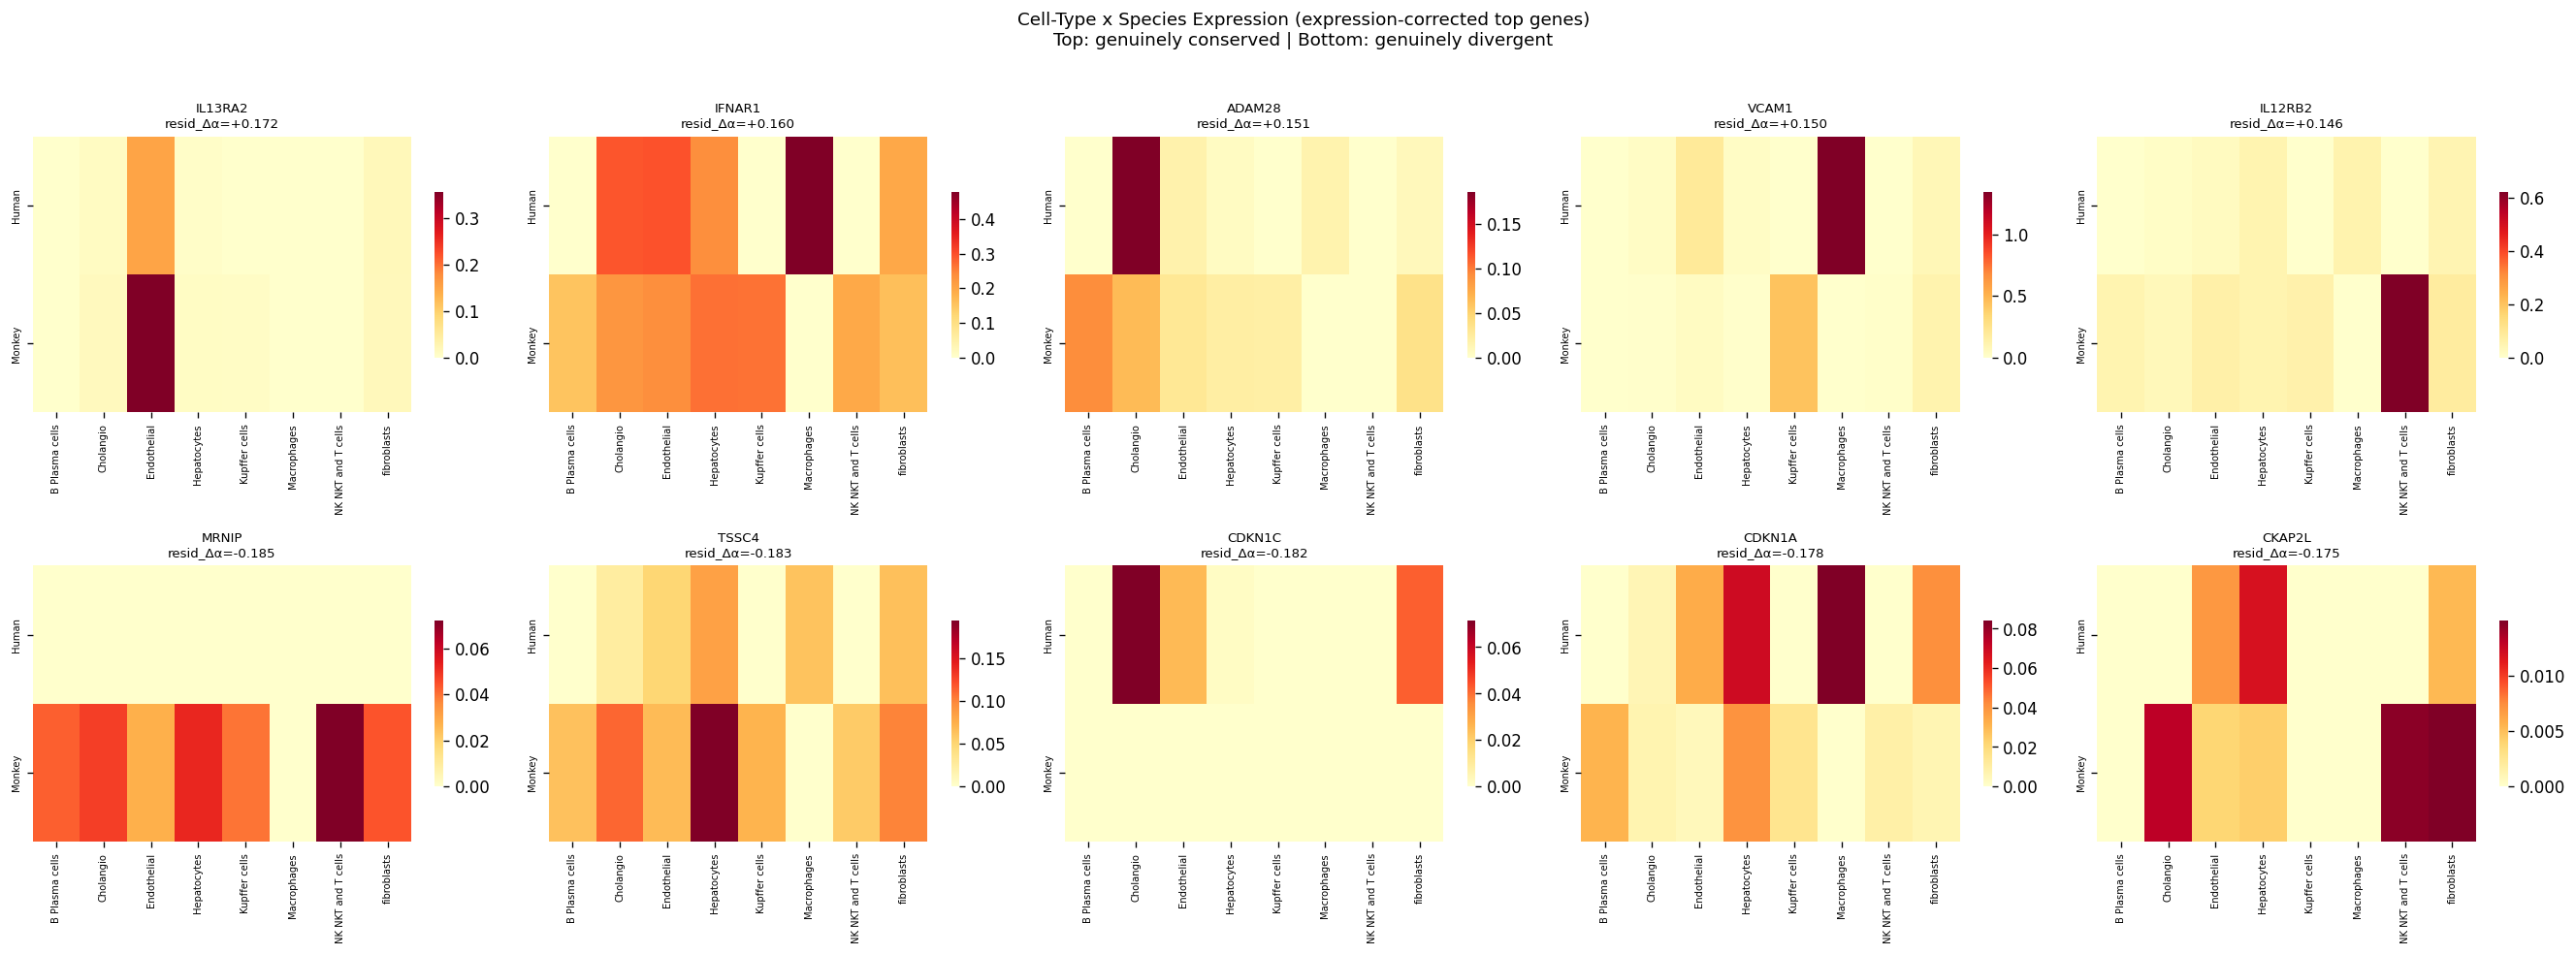

In [11]:
# Cell-type-level expression breakdown for top interesting genes
if ct_arr is not None:
    unique_ct = sorted(set(ct_arr))
    
    # Expression-corrected: top 5 positive + top 5 negative resid Δα
    interesting_idx = list(top_pos_resid[:5]) + list(top_neg_resid[:5])
    
    n_genes_show = len(interesting_idx)
    n_cols = min(5, n_genes_show)
    n_rows = (n_genes_show + n_cols - 1) // n_cols
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(4.5 * n_cols, 4 * n_rows), squeeze=False)
    
    for idx, g_idx in enumerate(interesting_idx):
        row, col = idx // n_cols, idx % n_cols
        ax = axes[row, col]
        
        heatmap_data = np.zeros((len(unique_sp), len(unique_ct)))
        for si, sp in enumerate(unique_sp):
            for ci, ct in enumerate(unique_ct):
                mask = (species_arr == sp) & (ct_arr == ct)
                if mask.sum() > 0:
                    heatmap_data[si, ci] = log_cpm[mask, g_idx].mean()
        
        sns.heatmap(heatmap_data, ax=ax, cmap="YlOrRd", 
                   xticklabels=unique_ct, yticklabels=unique_sp,
                   cbar=True, cbar_kws={"shrink": 0.6})
        ax.set_title(f"{real_names[g_idx]}\nresid_Δα={da_resid[g_idx]:+.3f}", fontsize=8)
        ax.tick_params(labelsize=6)
        if col > 0:
            ax.set_ylabel("")
    for idx in range(n_genes_show, n_rows * n_cols):
        axes[idx // n_cols, idx % n_cols].set_visible(False)
    
    fig.suptitle("Cell-Type x Species Expression (expression-corrected top genes)\n"
                 "Top: genuinely conserved | Bottom: genuinely divergent",
                fontsize=11, y=1.02)
    fig.tight_layout()
    plt.show()
else:
    print("No cell_type annotation available for cell-type breakdown")

## 4. Feature-Driven Gene Groups

What input features distinguish genes with positive vs negative delta-alpha?
This reveals what biological properties the GIN uses to override the prior.

=== Feature Profile by Delta-Alpha Group ===
                                ESM2_intersp_var  mean_identity  log_mean_expr  log_expr_var  frac_nonzero  std_identity  max_identity  min_identity  n_genes  mean_alpha  ESM2_PCA_norm
Strong positive (Δα>0.05)                 -0.132         -0.464          0.160         0.252         0.038           0.0           0.0           0.0    697.0       0.827          2.257
Weak positive (0.02<Δα<0.05)              -0.227          0.167          0.108         0.150         0.075           0.0           0.0           0.0    995.0       0.849          1.238
Neutral (|Δα|<0.02)                       -0.146          0.517          0.122         0.085         0.174           0.0           0.0           0.0   3120.0       0.848          0.604
Weak negative (-0.05<Δα<-0.02)             0.072          0.055          0.006        -0.013         0.030           0.0           0.0           0.0   1655.0       0.772          0.607
Strong negative (Δα<-0.05)    

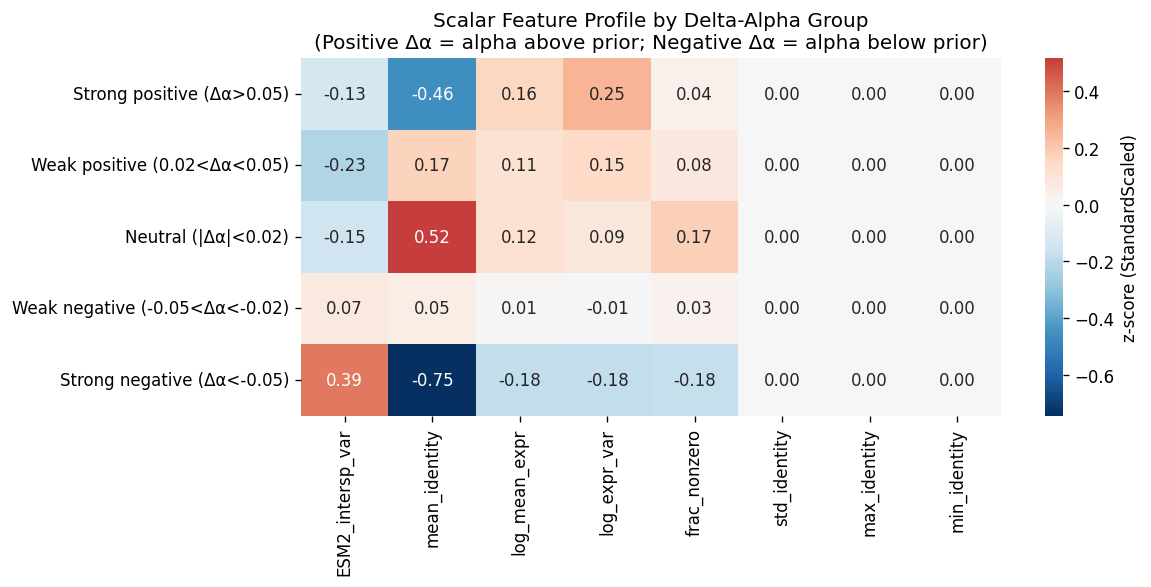

In [12]:
# Split genes into delta-alpha groups
da_groups = {
    "Strong positive (Δα>0.05)": delta_alpha > 0.05,
    "Weak positive (0.02<Δα<0.05)": (delta_alpha > 0.02) & (delta_alpha <= 0.05),
    "Neutral (|Δα|<0.02)": np.abs(delta_alpha) <= 0.02,
    "Weak negative (-0.05<Δα<-0.02)": (delta_alpha < -0.02) & (delta_alpha >= -0.05),
    "Strong negative (Δα<-0.05)": delta_alpha < -0.05,
}

# Mean feature value per group for scalar features
group_profiles = {}
for gname, mask in da_groups.items():
    group_profiles[gname] = {
        **{SCALAR_NAMES[i]: X_feat[mask, 64+i].mean() for i in range(8)},
        "n_genes": mask.sum(),
        "mean_alpha": alpha[mask].mean(),
        "ESM2_PCA_norm": np.linalg.norm(X_feat[mask, :64].mean(axis=0)),
    }

profile_df = pd.DataFrame(group_profiles).T
print("=== Feature Profile by Delta-Alpha Group ===")
print(profile_df.round(3).to_string())

# Heatmap
fig, ax = plt.subplots(figsize=(10, 5))
plot_data = profile_df[SCALAR_NAMES].astype(float)
sns.heatmap(plot_data, annot=True, fmt=".2f", cmap="RdBu_r", center=0,
            ax=ax, cbar_kws={"label": "z-score (StandardScaled)"})
ax.set_title("Scalar Feature Profile by Delta-Alpha Group\n"
             "(Positive Δα = alpha above prior; Negative Δα = alpha below prior)")
ax.set_ylabel("")
plt.tight_layout()
plt.show()

In [13]:
# Statistical test: which features differ between positive and negative delta-alpha genes?
pos_genes = delta_alpha > 0.02
neg_genes = delta_alpha < -0.02

print("=== Mann-Whitney U Tests: Positive vs Negative Δα Genes ===")
print(f"{'Feature':<25} {'U stat':>10} {'p-value':>12} {'pos mean':>10} {'neg mean':>10} {'effect':>10}")
print("-" * 80)
for i, name in enumerate(SCALAR_NAMES):
    vals_pos = X_feat[pos_genes, 64 + i]
    vals_neg = X_feat[neg_genes, 64 + i]
    u, p = mannwhitneyu(vals_pos, vals_neg, alternative="two-sided")
    effect = vals_pos.mean() - vals_neg.mean()
    sig = "***" if p < 0.001 else "**" if p < 0.01 else "*" if p < 0.05 else ""
    print(f"  {name:<23} {u:10.0f} {p:12.2e} {vals_pos.mean():10.3f} {vals_neg.mean():10.3f} {effect:+10.3f} {sig}")

=== Mann-Whitney U Tests: Positive vs Negative Δα Genes ===
Feature                       U stat      p-value   pos mean   neg mean     effect
--------------------------------------------------------------------------------
  ESM2_intersp_var           2261781     3.48e-53     -0.188      0.244     -0.432 ***
  mean_identity              3621096     5.11e-27     -0.093     -0.379     +0.287 ***
  log_mean_expr              3120487     2.52e-01      0.130     -0.095     +0.225 
  log_expr_var               3249358     2.92e-04      0.192     -0.106     +0.298 ***
  frac_nonzero               3026414     5.09e-01      0.060     -0.082     +0.142 
  std_identity               3060828     1.00e+00      0.000      0.000     +0.000 
  max_identity               3060828     1.00e+00      0.000      0.000     +0.000 
  min_identity               3060828     1.00e+00      0.000      0.000     +0.000 


## 5. ESM-2 Structural Properties and Expression Conservation

The 64 ESM-2 PCA dimensions capture protein structural information.
Do specific structural "directions" in protein embedding space predict
expression conservation beyond sequence identity?

This is a novel analysis: linking protein structure (ESM-2) to cross-species
expression conservation.

In [14]:
# Fit a linear model: delta_alpha ~ ESM2_PCA (64 dims)
# After controlling for sequence identity
esm2_pca = X_feat[:, :64]

# Model 1: delta_alpha ~ mean_identity only
lr_id = LinearRegression().fit(X_feat[:, 65:66], delta_alpha)
r2_id = lr_id.score(X_feat[:, 65:66], delta_alpha)

# Model 2: delta_alpha ~ ESM2 PCA only
lr_esm2 = LinearRegression().fit(esm2_pca, delta_alpha)
r2_esm2 = lr_esm2.score(esm2_pca, delta_alpha)

# Model 3: delta_alpha ~ ESM2 + identity + expression
lr_all = LinearRegression().fit(X_feat, delta_alpha)
r2_all = lr_all.score(X_feat, delta_alpha)

# Model 4: delta_alpha ~ expression stats only
lr_expr = LinearRegression().fit(X_feat[:, 66:69], delta_alpha)
r2_expr = lr_expr.score(X_feat[:, 66:69], delta_alpha)

print("=== Linear Prediction of Delta-Alpha (R-squared) ===")
print(f"  Mean identity only:     R² = {r2_id:.4f}")
print(f"  Expression stats only:  R² = {r2_expr:.4f}")
print(f"  ESM-2 PCA only:         R² = {r2_esm2:.4f}")
print(f"  All 72 features:        R² = {r2_all:.4f}")
print(f"\n  ESM-2 captures {r2_esm2 - r2_id:.4f} additional variance beyond sequence identity")
print(f"  All features capture {r2_all - r2_id:.4f} additional variance beyond identity")

=== Linear Prediction of Delta-Alpha (R-squared) ===
  Mean identity only:     R² = 0.0891
  Expression stats only:  R² = 0.0251
  ESM-2 PCA only:         R² = 0.8807
  All 72 features:        R² = 0.8929

  ESM-2 captures 0.7915 additional variance beyond sequence identity
  All features capture 0.8037 additional variance beyond identity


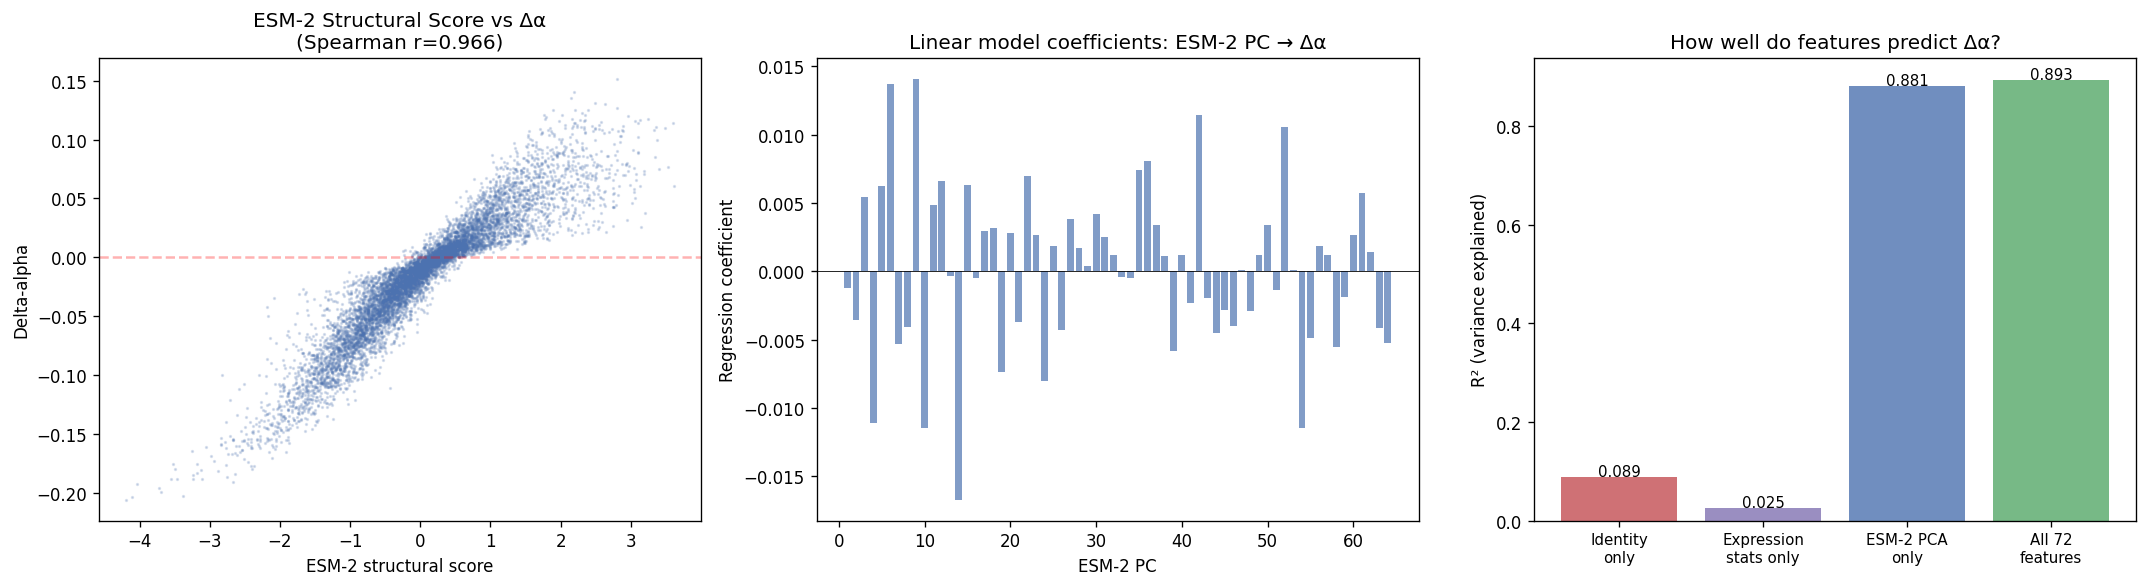

In [15]:
# Find the linear direction in ESM-2 space most predictive of delta-alpha
# This is the ESM-2 PCA coefficient vector from the linear model
esm2_direction = lr_esm2.coef_  # (64,) — the direction in ESM-2 space predicting Δα
esm2_direction_norm = esm2_direction / np.linalg.norm(esm2_direction)

# Project all genes onto this direction
esm2_score = esm2_pca @ esm2_direction_norm  # (G,) — "conservation-predictive" structural score

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# (a) ESM-2 structural score vs delta-alpha
ax = axes[0]
ax.scatter(esm2_score, delta_alpha, s=1, alpha=0.2, c="#4C72B0")
r_esm2_da = spearmanr(esm2_score, delta_alpha).correlation
ax.set_xlabel("ESM-2 structural score")
ax.set_ylabel("Delta-alpha")
ax.set_title(f"ESM-2 Structural Score vs Δα\n(Spearman r={r_esm2_da:.3f})")
ax.axhline(0, color="red", linestyle="--", alpha=0.3)

# (b) ESM-2 direction coefficients (which PCs matter)
ax = axes[1]
ax.bar(range(1, 65), lr_esm2.coef_, color="#4C72B0", alpha=0.7)
ax.set_xlabel("ESM-2 PC")
ax.set_ylabel("Regression coefficient")
ax.set_title("Linear model coefficients: ESM-2 PC → Δα")
ax.axhline(0, color="black", linewidth=0.5)

# (c) R² comparison
ax = axes[2]
models = ["Identity\nonly", "Expression\nstats only", "ESM-2 PCA\nonly", "All 72\nfeatures"]
r2s = [r2_id, r2_expr, r2_esm2, r2_all]
colors = ["#C44E52", "#8172B2", "#4C72B0", "#55A868"]
ax.bar(range(4), r2s, color=colors, alpha=0.8)
ax.set_xticks(range(4))
ax.set_xticklabels(models, fontsize=9)
ax.set_ylabel("R² (variance explained)")
ax.set_title("How well do features predict Δα?")
for i, r2 in enumerate(r2s):
    ax.text(i, r2 + 0.002, f"{r2:.3f}", ha="center", fontsize=9)

fig.tight_layout()
plt.show()

## 6. Confound Control

Verify that GIN corrections reflect biology, not technical artifacts.
Test whether correction correlates with known confounds:
- Expression level (highly expressed genes have less noise)
- Dropout rate (sparse genes have unreliable gradients)
- Gene variability

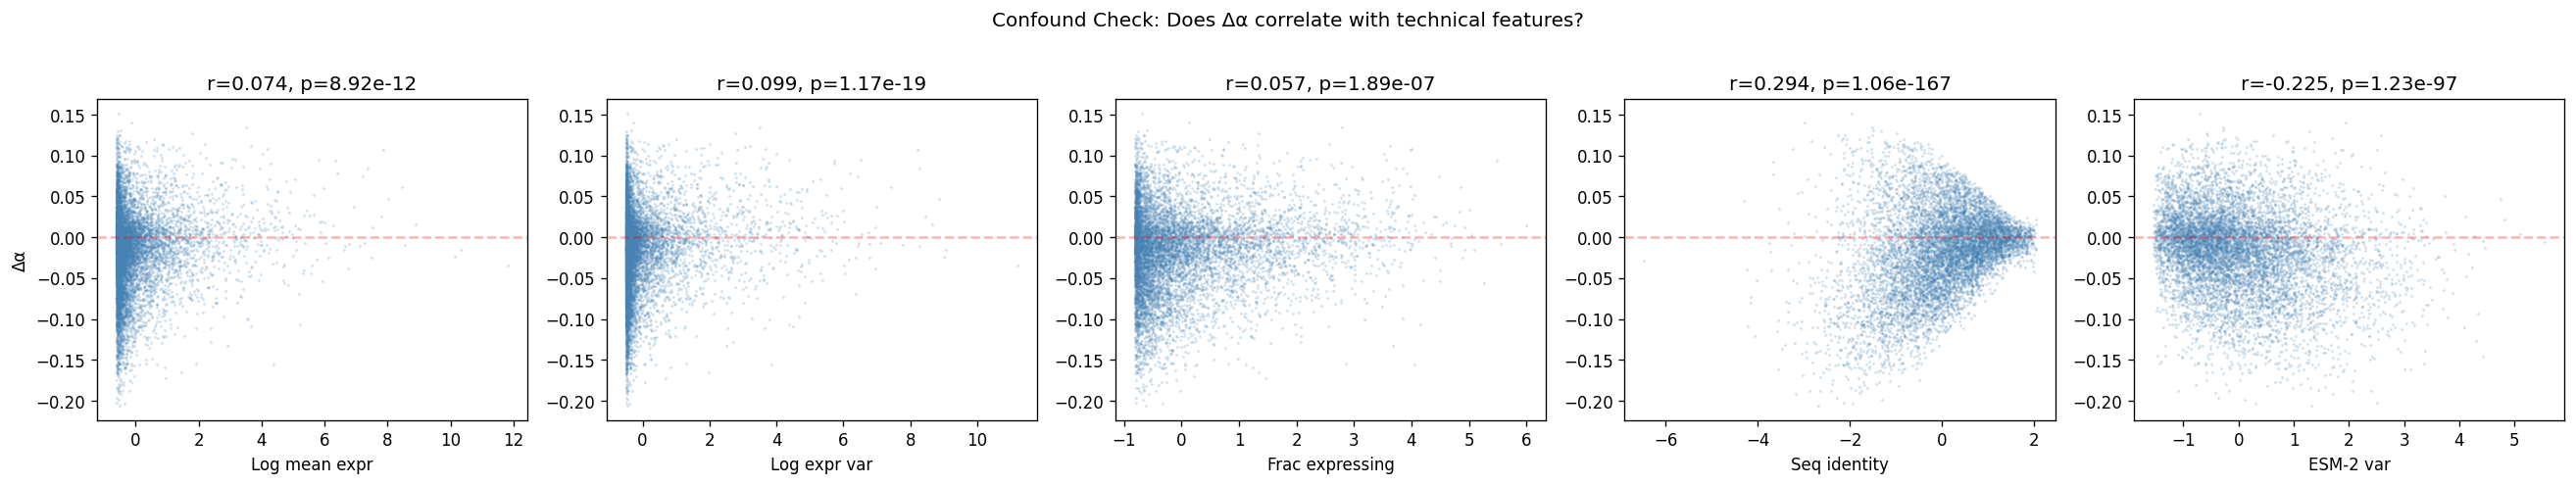


Confound regression R² = 0.1314
Correlation of raw Δα with residualized Δα: 0.917
(High correlation = most Δα signal survives confound removal = biology, not artifacts)


In [16]:
# Confound analysis
confound_names = ["log_mean_expr_feat", "log_expr_var_feat", "frac_nonzero_feat",
                  "mean_identity", "esm2_var"]
confound_labels = ["Log mean expr", "Log expr var", "Frac expressing",
                   "Seq identity", "ESM-2 var"]

fig, axes = plt.subplots(1, 5, figsize=(22, 4))
for ax, cname, clabel in zip(axes, confound_names, confound_labels):
    vals = gene_df[cname].values
    r, p = spearmanr(vals, delta_alpha)
    ax.scatter(vals, delta_alpha, s=1, alpha=0.15, c="steelblue")
    ax.axhline(0, color="red", linestyle="--", alpha=0.3)
    ax.set_xlabel(clabel)
    ax.set_ylabel("Δα" if ax == axes[0] else "")
    ax.set_title(f"r={r:.3f}, p={p:.2e}")

fig.suptitle("Confound Check: Does Δα correlate with technical features?", fontsize=12, y=1.02)
fig.tight_layout()
plt.show()

# Residualize delta-alpha against confounds
confound_matrix = gene_df[confound_names].values
lr_confound = LinearRegression().fit(confound_matrix, delta_alpha)
da_residualized = delta_alpha - lr_confound.predict(confound_matrix)

print(f"\nConfound regression R² = {lr_confound.score(confound_matrix, delta_alpha):.4f}")
print(f"Correlation of raw Δα with residualized Δα: {spearmanr(delta_alpha, da_residualized).correlation:.3f}")
print("(High correlation = most Δα signal survives confound removal = biology, not artifacts)")

## 7. GIN Correction Trajectory During Training

How do GIN corrections evolve during training? Early corrections are noise;
stable late corrections reflect learned biology.

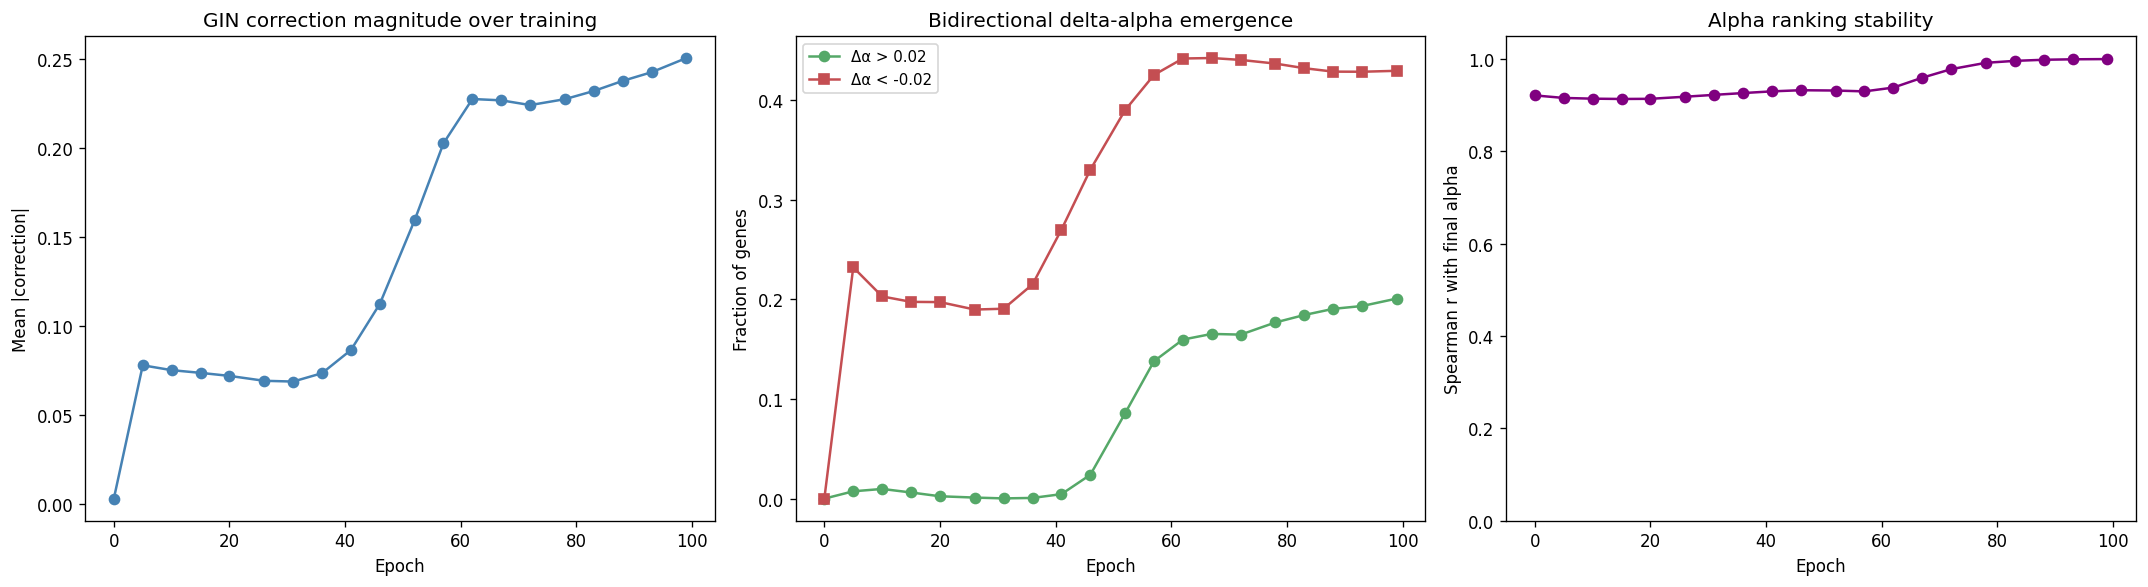

Alpha ranking stabilizes (r>0.95 with final) at epoch: 67


In [17]:
# Load alpha snapshots to track evolution
snapshot_dir = RUN_DIR / "alpha_snapshots"
snapshot_files = sorted(snapshot_dir.glob("alpha_epoch_*.npz"))

if len(snapshot_files) > 0:
    epochs_to_sample = np.linspace(0, len(snapshot_files) - 1, min(20, len(snapshot_files))).astype(int)
    
    alphas_over_time = []
    corrections_over_time = []
    epoch_nums = []
    
    for ei in epochs_to_sample:
        data = np.load(snapshot_files[ei])
        alphas_over_time.append(data["alpha"] if "alpha" in data else None)
        corrections_over_time.append(data["correction"] if "correction" in data else None)
        epoch_nums.append(int(snapshot_files[ei].stem.split("_")[-1]))
    
    # Filter out None entries
    valid = [(e, a, c) for e, a, c in zip(epoch_nums, alphas_over_time, corrections_over_time)
             if a is not None and c is not None]
    
    if valid:
        epoch_nums_v, alphas_v, corrections_v = zip(*valid)
        
        fig, axes = plt.subplots(1, 3, figsize=(18, 5))
        
        # (a) Mean |correction| over epochs
        ax = axes[0]
        mean_abs_corr = [np.abs(c).mean() for c in corrections_v]
        ax.plot(epoch_nums_v, mean_abs_corr, "o-", color="steelblue")
        ax.set_xlabel("Epoch")
        ax.set_ylabel("Mean |correction|")
        ax.set_title("GIN correction magnitude over training")
        
        # (b) Fraction positive delta-alpha over epochs
        ax = axes[1]
        frac_pos = [(a > prior + 0.02).mean() for a in alphas_v]
        frac_neg = [(a < prior - 0.02).mean() for a in alphas_v]
        ax.plot(epoch_nums_v, frac_pos, "o-", color="#55A868", label="Δα > 0.02")
        ax.plot(epoch_nums_v, frac_neg, "s-", color="#C44E52", label="Δα < -0.02")
        ax.set_xlabel("Epoch")
        ax.set_ylabel("Fraction of genes")
        ax.set_title("Bidirectional delta-alpha emergence")
        ax.legend(fontsize=9)
        
        # (c) Alpha ranking stability (Spearman r with final)
        ax = axes[2]
        final_alpha = alphas_v[-1]
        stab = [spearmanr(a, final_alpha).correlation for a in alphas_v]
        ax.plot(epoch_nums_v, stab, "o-", color="purple")
        ax.set_xlabel("Epoch")
        ax.set_ylabel("Spearman r with final alpha")
        ax.set_title("Alpha ranking stability")
        ax.set_ylim(0, 1.05)
        
        fig.tight_layout()
        plt.show()
        
        # When does alpha stabilize?
        stable_epoch = next((e for e, s in zip(epoch_nums_v, stab) if s > 0.95), None)
        print(f"Alpha ranking stabilizes (r>0.95 with final) at epoch: {stable_epoch}")
    else:
        print("No valid alpha/correction snapshots found")
else:
    print("No alpha snapshots found")

## 8. Cross-Gene Correlation Structure

Do genes with similar GIN representations have similar biological properties?
Analyze the correlation between GIN distance and expression pattern similarity.

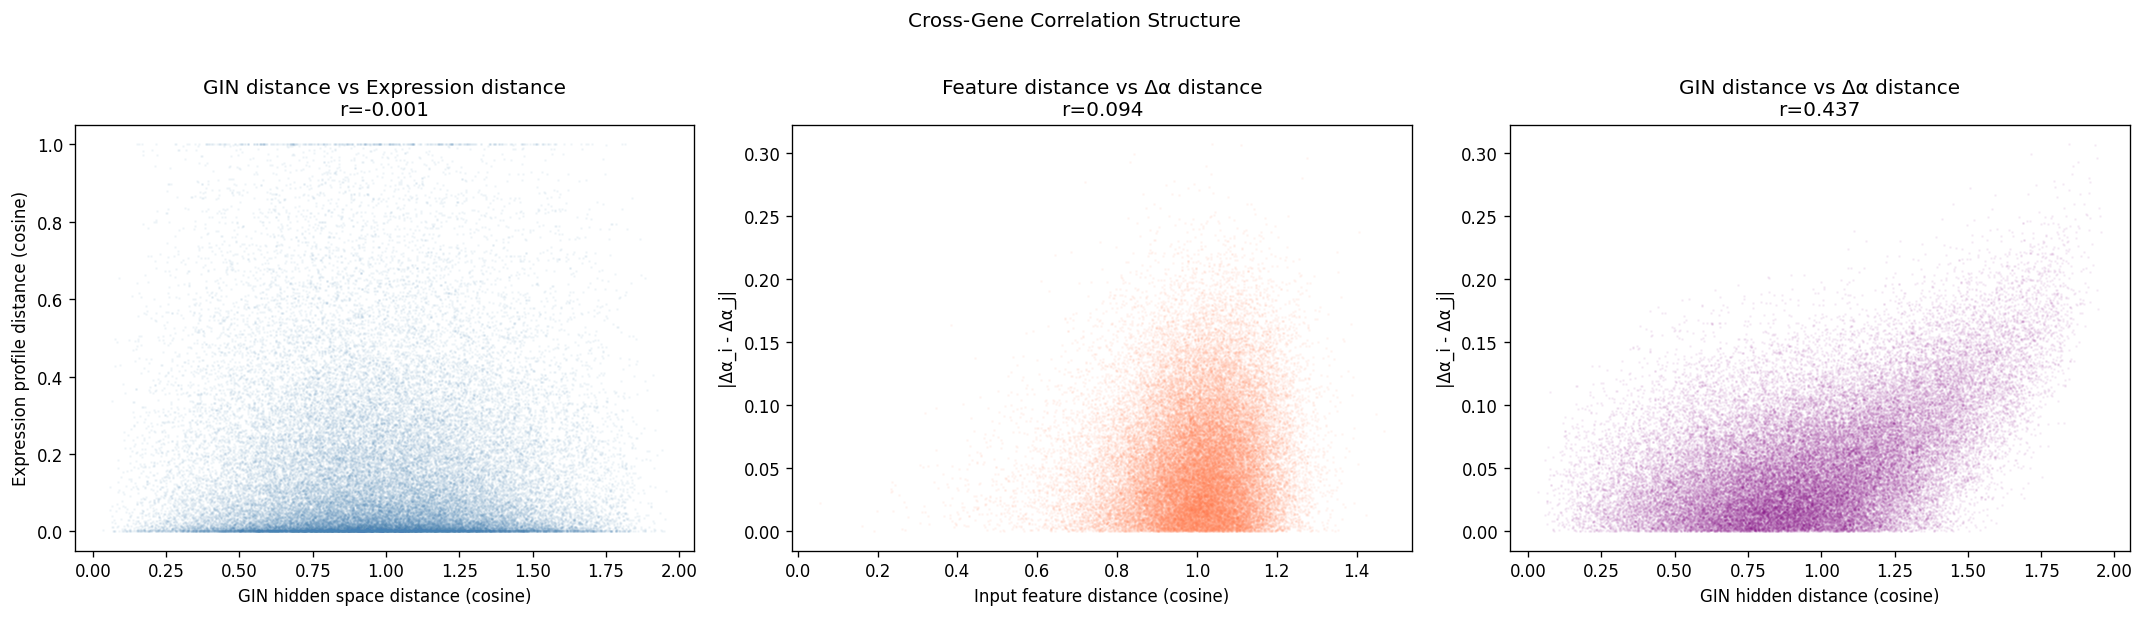


Correlations (Spearman, pairwise gene distances):
  GIN distance ~ Expression distance:  r = -0.001
  Feature distance ~ Δα distance:      r = 0.094
  GIN distance ~ Δα distance:          r = 0.437


In [18]:
# Sample genes for pairwise analysis (full pairwise is O(G^2))
np.random.seed(42)
sample_idx = np.random.choice(G, min(2000, G), replace=False)

# GIN hidden space distance
H_sample = H[sample_idx]
gin_dist = squareform(pdist(H_sample, metric="cosine"))

# Expression profile distance (cosine of mean expression across species)
expr_profiles = np.column_stack([log_mean_profiles[sp][sample_idx] for sp in unique_sp])  # (n_sample, n_sp)
expr_dist = squareform(pdist(expr_profiles, metric="cosine"))

# Delta-alpha distance
da_sample = delta_alpha[sample_idx]
da_dist = squareform(pdist(da_sample.reshape(-1, 1), metric="euclidean"))

# Feature distance
feat_dist = squareform(pdist(X_feat[sample_idx], metric="cosine"))

# Flatten upper triangle for correlation
triu_idx = np.triu_indices(len(sample_idx), k=1)
gin_flat = gin_dist[triu_idx]
expr_flat = expr_dist[triu_idx]
da_flat = da_dist[triu_idx]
feat_flat = feat_dist[triu_idx]

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# (a) GIN distance vs expression distance
ax = axes[0]
# Subsample for plotting
plot_idx = np.random.choice(len(gin_flat), min(50000, len(gin_flat)), replace=False)
ax.scatter(gin_flat[plot_idx], expr_flat[plot_idx], s=0.5, alpha=0.05, c="steelblue")
r_ge = spearmanr(gin_flat[plot_idx], expr_flat[plot_idx]).correlation
ax.set_xlabel("GIN hidden space distance (cosine)")
ax.set_ylabel("Expression profile distance (cosine)")
ax.set_title(f"GIN distance vs Expression distance\nr={r_ge:.3f}")

# (b) Feature distance vs delta-alpha distance
ax = axes[1]
ax.scatter(feat_flat[plot_idx], da_flat[plot_idx], s=0.5, alpha=0.05, c="coral")
r_fd = spearmanr(feat_flat[plot_idx], da_flat[plot_idx]).correlation
ax.set_xlabel("Input feature distance (cosine)")
ax.set_ylabel("|Δα_i - Δα_j|")
ax.set_title(f"Feature distance vs Δα distance\nr={r_fd:.3f}")

# (c) GIN distance vs delta-alpha distance
ax = axes[2]
ax.scatter(gin_flat[plot_idx], da_flat[plot_idx], s=0.5, alpha=0.05, c="purple")
r_gd = spearmanr(gin_flat[plot_idx], da_flat[plot_idx]).correlation
ax.set_xlabel("GIN hidden distance (cosine)")
ax.set_ylabel("|Δα_i - Δα_j|")
ax.set_title(f"GIN distance vs Δα distance\nr={r_gd:.3f}")

fig.suptitle("Cross-Gene Correlation Structure", fontsize=12, y=1.02)
fig.tight_layout()
plt.show()

print(f"\nCorrelations (Spearman, pairwise gene distances):")
print(f"  GIN distance ~ Expression distance:  r = {r_ge:.3f}")
print(f"  Feature distance ~ Δα distance:      r = {r_fd:.3f}")
print(f"  GIN distance ~ Δα distance:          r = {r_gd:.3f}")

## 9. Novel Biological Findings Summary

Compile all findings into a structured summary.

In [19]:
print("=" * 75)
print("  CROSS-GENE BIOLOGICAL FINDINGS — SUMMARY")
print("=" * 75)

print(f"\n1. GENE ARCHETYPES ({best_k} clusters from GIN hidden space):")
for a in range(best_k):
    n = (gene_df["archetype"] == a).sum()
    da_mean = gene_df[gene_df["archetype"] == a]["delta_alpha"].mean()
    a_mean = gene_df[gene_df["archetype"] == a]["alpha"].mean()
    print(f"   Archetype {a}: {n:5d} genes, mean α={a_mean:.3f}, mean Δα={da_mean:+.4f}")

print(f"\n2. IDENTITY-EXPRESSION DISCORDANCE:")
for name, mask in quadrants.items():
    da = delta_alpha[mask]
    print(f"   {name.split(chr(10))[0]:<35} n={mask.sum():5d}  mean Δα={da.mean():+.4f}")

print(f"\n3. ESM-2 STRUCTURAL PREDICTION:")
print(f"   Seq identity alone explains {r2_id:.1%} of Δα variance")
print(f"   ESM-2 PCA alone explains    {r2_esm2:.1%} of Δα variance")
print(f"   All 72 features explain     {r2_all:.1%} of Δα variance")
print(f"   => ESM-2 adds {r2_esm2 - r2_id:.1%} beyond identity (protein structure matters!)")

print(f"\n4. CONFOUND CONTROL:")
confound_r2 = lr_confound.score(confound_matrix, delta_alpha)
print(f"   Confound R² = {confound_r2:.4f}")
print(f"   Δα after confound removal correlates {spearmanr(delta_alpha, da_residualized).correlation:.3f} with raw Δα")

print(f"\n5. CROSS-GENE STRUCTURE:")
print(f"   GIN distance ~ Expr distance:  r = {r_ge:.3f} (genes nearby in GIN space have similar expression)")
print(f"   Feature distance ~ Δα distance: r = {r_fd:.3f} (similar features → similar integration)")

print(f"\n6. TOP REGULATORY DIVERGENCE GENES (high seq ID, divergent expression):")
_q2_idx = [i for i in np.argsort(delta_alpha) if q2[i]][:5]
for i in _q2_idx:
    g = gene_df.index[i]
    print(f"   {g:<15} α={gene_df.iloc[i]['alpha']:.3f}  prior={gene_df.iloc[i]['prior']:.3f}  "
          f"Δα={gene_df.iloc[i]['delta_alpha']:+.3f}  expr_div={gene_df.iloc[i]['expr_divergence']:.3f}")

print(f"\n7. TOP CONVERGENT EXPRESSION GENES (low seq ID, conserved expression):")
_q3_idx = [i for i in np.argsort(-delta_alpha) if q3[i]][:5]
for i in _q3_idx:
    g = gene_df.index[i]
    print(f"   {g:<15} α={gene_df.iloc[i]['alpha']:.3f}  prior={gene_df.iloc[i]['prior']:.3f}  "
          f"Δα={gene_df.iloc[i]['delta_alpha']:+.3f}  expr_div={gene_df.iloc[i]['expr_divergence']:.3f}")

print("\n" + "=" * 75)

  CROSS-GENE BIOLOGICAL FINDINGS — SUMMARY

1. GENE ARCHETYPES (3 clusters from GIN hidden space):
   Archetype 0:  3705 genes, mean α=0.812, mean Δα=-0.0068
   Archetype 1:  2909 genes, mean α=0.696, mean Δα=-0.0700
   Archetype 2:  1816 genes, mean α=0.862, mean Δα=+0.0460

2. IDENTITY-EXPRESSION DISCORDANCE:
   Q1: Housekeeping                    n= 1997  mean Δα=-0.0050
   Q2: Regulatory divergence           n= 2218  mean Δα=-0.0045
   Q3: Convergent expression           n= 2218  mean Δα=-0.0315
   Q4: Fully divergent                 n= 1997  mean Δα=-0.0277

3. ESM-2 STRUCTURAL PREDICTION:
   Seq identity alone explains 8.9% of Δα variance
   ESM-2 PCA alone explains    88.1% of Δα variance
   All 72 features explain     89.3% of Δα variance
   => ESM-2 adds 79.2% beyond identity (protein structure matters!)

4. CONFOUND CONTROL:
   Confound R² = 0.1314
   Δα after confound removal correlates 0.917 with raw Δα

5. CROSS-GENE STRUCTURE:
   GIN distance ~ Expr distance:  r = -0.001 

In [20]:
# Export key results with round2 caveat annotations
output_dir = REPO / "training" / "runs" / "iter31-mmd1k-masked-detached" / "tables"
output_dir.mkdir(exist_ok=True)

export_df = gene_df.copy()
export_df["da_residualized"] = da_resid
export_df["esm2_structural_score"] = esm2_score
export_df["da_rank"] = pd.Series(delta_alpha).rank(ascending=False).values.astype(int)
export_df["mechanism"] = np.where(
    (S_g > 0) & (delta_alpha > 0.02), "FQR-driven",
    np.where((S_g == 0) & (delta_alpha < -0.02), "recon-driven",
             np.where((S_g > 0) & (delta_alpha < 0), "overlap", "neutral")))
export_df["flag_positive_unreliable"] = (S_g > 0) & (delta_alpha > 0.02)
export_df["flag_overlap"] = (S_g > 0) & (delta_alpha < 0)
export_df.to_csv(output_dir / "cross_gene_analysis.csv")

# Top expression-corrected genes
resid_pos = gene_df.iloc[np.argsort(-da_resid)[:50]][["gene_name","alpha","prior","delta_alpha","S_g","expr_divergence"]]
resid_pos["da_residualized"] = da_resid[np.argsort(-da_resid)[:50]]
resid_neg = gene_df.iloc[np.argsort(da_resid)[:50]][["gene_name","alpha","prior","delta_alpha","S_g","expr_divergence"]]
resid_neg["da_residualized"] = da_resid[np.argsort(da_resid)[:50]]
resid_pos.to_csv(output_dir / "top_conserved_expression_corrected.csv")
resid_neg.to_csv(output_dir / "top_divergent_expression_corrected.csv")

# Reliable negative-tail genes (recon-driven, no caveats)
reliable = export_df[
    (export_df["mechanism"] == "recon-driven") & (export_df["delta_alpha"] < -0.1)
].sort_values("delta_alpha")
reliable.to_csv(output_dir / "reliable_divergent_genes.csv")

print(f"Exported to {output_dir}:")
print(f"  cross_gene_analysis.csv ({len(export_df)} genes, all metrics + caveat flags)")
print(f"  top_conserved_expression_corrected.csv (50 genes)")
print(f"  top_divergent_expression_corrected.csv (50 genes)")
print(f"  reliable_divergent_genes.csv ({len(reliable)} genes, recon-driven, no flags)")
print(f"\nCaveat flags in cross_gene_analysis.csv:")
print(f"  flag_positive_unreliable: {export_df['flag_positive_unreliable'].sum()} ({export_df['flag_positive_unreliable'].mean():.1%})")
print(f"  flag_overlap:             {export_df['flag_overlap'].sum()} ({export_df['flag_overlap'].mean():.1%})")
print(f"  mechanism=recon-driven:   {(export_df['mechanism']=='recon-driven').sum()} (most reliable)")

Exported to /Users/kemalinecik/git_nosync/master_chimera/chimera/training/runs/iter31-mmd1k-masked-detached/tables:
  cross_gene_analysis.csv (8430 genes, all metrics + caveat flags)
  top_conserved_expression_corrected.csv (50 genes)
  top_divergent_expression_corrected.csv (50 genes)
  reliable_divergent_genes.csv (270 genes, recon-driven, no flags)

Caveat flags in cross_gene_analysis.csv:
  flag_positive_unreliable: 995 (11.8%)
  flag_overlap:             3202 (38.0%)
  mechanism=recon-driven:   1507 (most reliable)


## 10. Biological Ground-Truth Validation

Test alpha against known biology: hepatocyte markers (expected conserved),
ribosomal proteins (expected neutral), mitochondrial genes (expected conserved),
cell-cycle regulators (expected divergent).

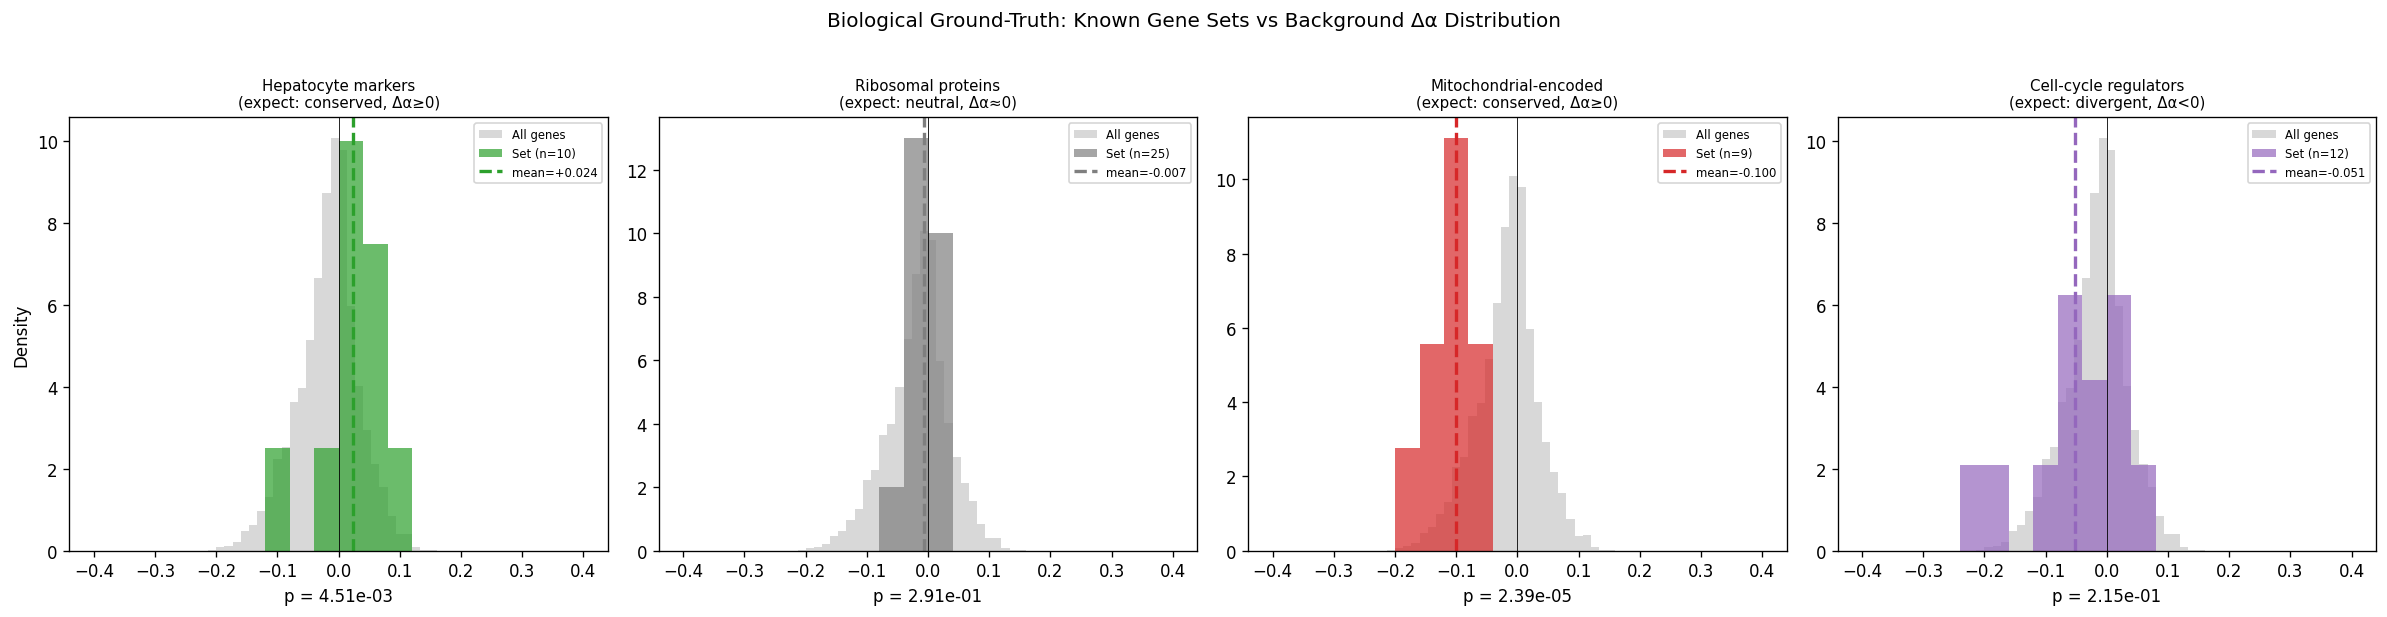

Gene Set                               n   mean Δα  mean resid   mean α      p-value
-------------------------------------------------------------------------------------
Hepatocyte markers                    10   +0.0240     +0.0289    0.732     4.51e-03
Ribosomal proteins                    25   -0.0073     +0.0099    0.922     2.91e-01
Mitochondrial-encoded                  9   -0.1000     -0.0946    0.622     2.39e-05
Cell-cycle regulators                 12   -0.0512     -0.0318    0.740     2.15e-01


In [21]:
name_to_idx = {n: i for i, n in enumerate(real_names)}

gene_sets = {
    'Hepatocyte markers\n(expect: conserved, Δα≥0)': {
        'genes': ['ALB','APOA1','APOA2','APOB','APOC3','TF','TTR','FGA','FGB','FGG',
                  'HP','HPX','SERPINA1','AHSG','GC','RBP4','AMBP','AGT','ASGR1','HNF4A'],
        'expected_sign': 'positive', 'color': '#2ca02c'},
    'Ribosomal proteins\n(expect: neutral, Δα≈0)': {
        'genes': [f'RPL{i}' for i in [3,4,5,6,7,8,9,10,11,12,13,14,15,17,18,19,21,22,24,26,27,28,29,30,31,35]] +
                 [f'RPS{i}' for i in [2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,23,24,25,26,27,28,29]],
        'expected_sign': 'neutral', 'color': '#7f7f7f'},
    'Mitochondrial-encoded\n(expect: conserved, Δα≥0)': {
        'genes': ['MT-ND1','MT-ND2','MT-ND3','MT-ND4','MT-ND5','MT-ND6',
                  'MT-CO1','MT-CO2','MT-CO3','MT-CYB','MT-ATP6','MT-ATP8'],
        'expected_sign': 'positive', 'color': '#d62728'},
    'Cell-cycle regulators\n(expect: divergent, Δα<0)': {
        'genes': ['CDKN1A','CDKN1B','CDKN1C','CDKN2A','CDKN2B','CDK1','CDK2','CDK4',
                  'CDK6','CCNA2','CCNB1','CCND1','CCNE1','RB1','TP53','MYC','E2F1'],
        'expected_sign': 'negative', 'color': '#9467bd'},
}

fig, axes = plt.subplots(1, 4, figsize=(20, 5))
for ax, (setname, info) in zip(axes, gene_sets.items()):
    idx = [name_to_idx[g] for g in info['genes'] if g in name_to_idx]
    if len(idx) < 2:
        ax.set_title(f"{setname}\n(< 2 genes found)"); continue
    da_set = delta_alpha[idx]
    ax.hist(delta_alpha, bins=60, range=(-0.4, 0.4), density=True, alpha=0.3,
            color='gray', edgecolor='none', label='All genes')
    ax.hist(da_set, bins=20, range=(-0.4, 0.4), density=True, alpha=0.7,
            color=info['color'], edgecolor='none', label=f'Set (n={len(idx)})')
    ax.axvline(0, color='black', linewidth=0.5)
    ax.axvline(da_set.mean(), color=info['color'], linewidth=2, linestyle='--',
              label=f'mean={da_set.mean():+.3f}')
    if len(idx) >= 3:
        _, p = mannwhitneyu(da_set, delta_alpha, alternative='two-sided')
        ax.set_xlabel(f'p = {p:.2e}')
    ax.set_title(setname, fontsize=9)
    ax.legend(fontsize=7)
    ax.set_ylabel('Density' if ax == axes[0] else '')

fig.suptitle('Biological Ground-Truth: Known Gene Sets vs Background Δα Distribution',
             fontsize=12, y=1.02)
fig.tight_layout()
plt.show()

print(f"{'Gene Set':<35} {'n':>4} {'mean Δα':>9} {'mean resid':>11} {'mean α':>8} {'p-value':>12}")
print('-' * 85)
for setname, info in gene_sets.items():
    idx = [name_to_idx[g] for g in info['genes'] if g in name_to_idx]
    if len(idx) < 2: continue
    da_s = delta_alpha[idx]
    _, p = mannwhitneyu(da_s, delta_alpha, alternative='two-sided') if len(idx)>=3 else (0,1)
    print(f"{setname.split(chr(10))[0]:<35} {len(idx):>4} {da_s.mean():+9.4f} {da_resid[idx].mean():+11.4f} "
          f"{alpha[idx].mean():8.3f} {p:12.2e}")

## 11. FQR-Driven vs Reconstruction-Driven Genes

Genes with positive Δα are driven by the FQR (S_g > 0); genes with negative Δα
and S_g = 0 are driven purely by reconstruction loss. Round2 warns the positive
tail is less reliable. Overlap genes (S_g > 0 but Δα < 0) have both forces active.

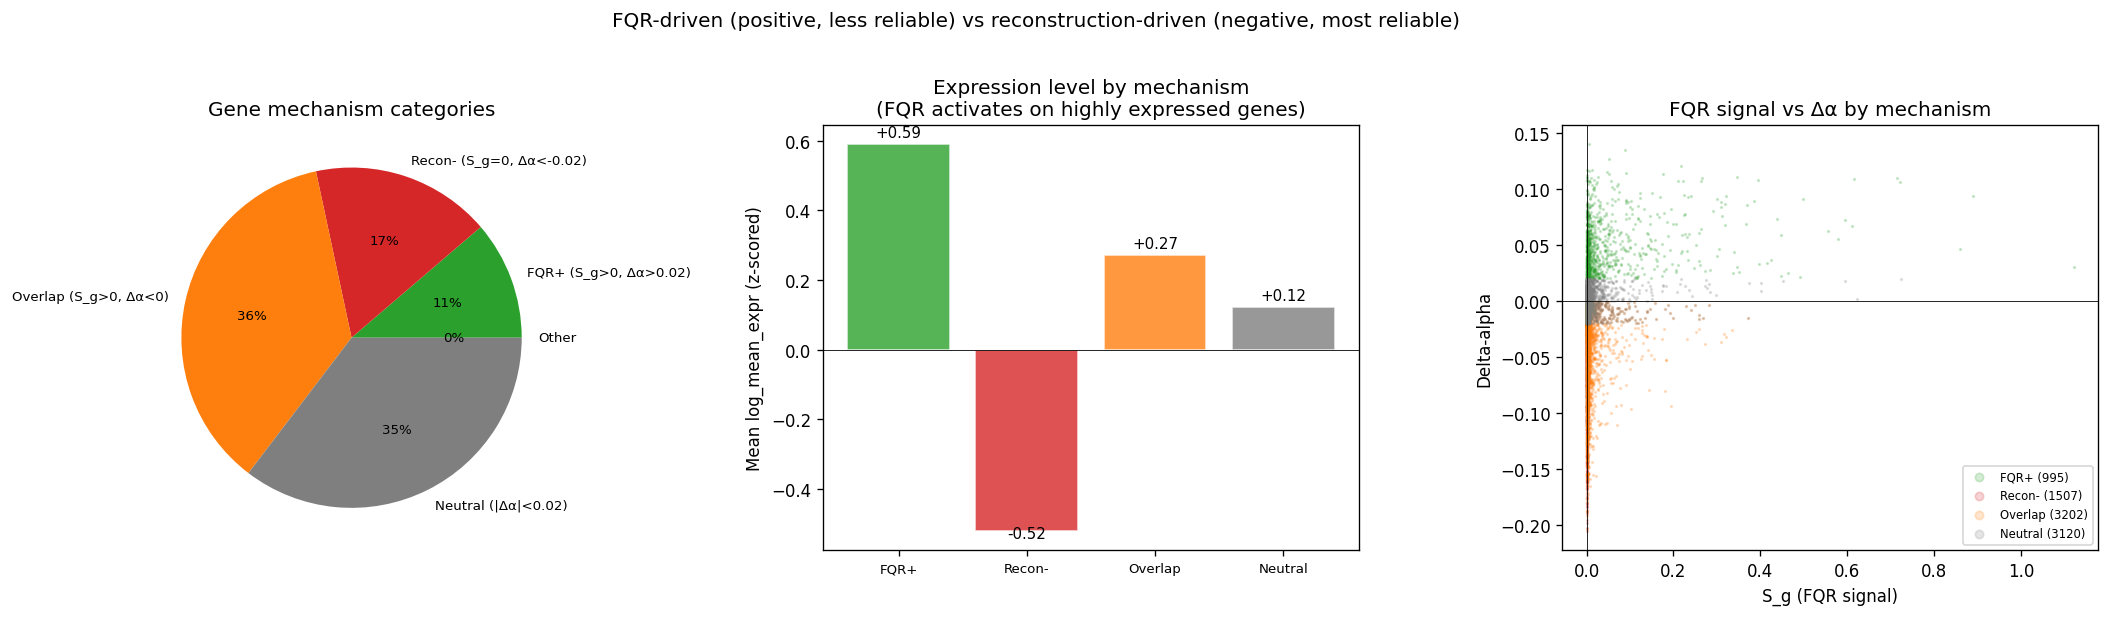

In [22]:
cats = {
    'FQR+ (S_g>0, Δα>0.02)': (S_g > 0) & (delta_alpha > 0.02),
    'Recon- (S_g=0, Δα<-0.02)': (S_g == 0) & (delta_alpha < -0.02),
    'Overlap (S_g>0, Δα<0)': (S_g > 0) & (delta_alpha < 0),
    'Neutral (|Δα|<0.02)': np.abs(delta_alpha) <= 0.02,
}

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
cat_colors = ['#2ca02c', '#d62728', '#ff7f0e', '#7f7f7f']

# (a) Pie chart
ax = axes[0]
sizes = [m.sum() for m in cats.values()]
other = max(0, G - sum(sizes)); sizes.append(other)
wedges, texts, autotexts = ax.pie(sizes, labels=list(cats.keys()) + ['Other'],
    autopct='%1.0f%%', colors=cat_colors + ['#aec7e8'], textprops={'fontsize': 8})
ax.set_title('Gene mechanism categories')

# (b) Expression level by category
ax = axes[1]
expr_means = [X_feat[m, 66].mean() for m in cats.values()]
bars = ax.bar(range(4), expr_means, color=cat_colors, alpha=0.8, edgecolor='white')
ax.set_xticks(range(4))
ax.set_xticklabels([k.split('(')[0].strip() for k in cats], fontsize=8)
ax.set_ylabel('Mean log_mean_expr (z-scored)')
ax.set_title('Expression level by mechanism\n(FQR activates on highly expressed genes)')
ax.axhline(0, color='black', linewidth=0.5)
for bar, v in zip(bars, expr_means):
    ax.text(bar.get_x()+bar.get_width()/2, v + 0.02*np.sign(v), f'{v:+.2f}', ha='center', fontsize=9)

# (c) S_g vs delta-alpha colored by category
ax = axes[2]
for (name, mask), c in zip(cats.items(), cat_colors):
    ax.scatter(S_g[mask], delta_alpha[mask], s=1, alpha=0.2, c=c,
              label=f"{name.split('(')[0].strip()} ({mask.sum()})", rasterized=True)
ax.axhline(0, color='black', linewidth=0.5)
ax.axvline(0, color='black', linewidth=0.5)
ax.set_xlabel('S_g (FQR signal)'); ax.set_ylabel('Delta-alpha')
ax.set_title('FQR signal vs Δα by mechanism')
ax.legend(fontsize=7, markerscale=5)

fig.suptitle('FQR-driven (positive, less reliable) vs reconstruction-driven (negative, most reliable)',
             fontsize=12, y=1.02)
fig.tight_layout()
plt.show()

## 12. Cell-Type-Level Alpha Analysis (Caveat 32)

Alpha is per-gene (global), but expression divergence may be cell-type-specific.
Genes with high variability in divergence across cell types have unreliable alpha
(species x cell-type interaction the linear residual cannot model).

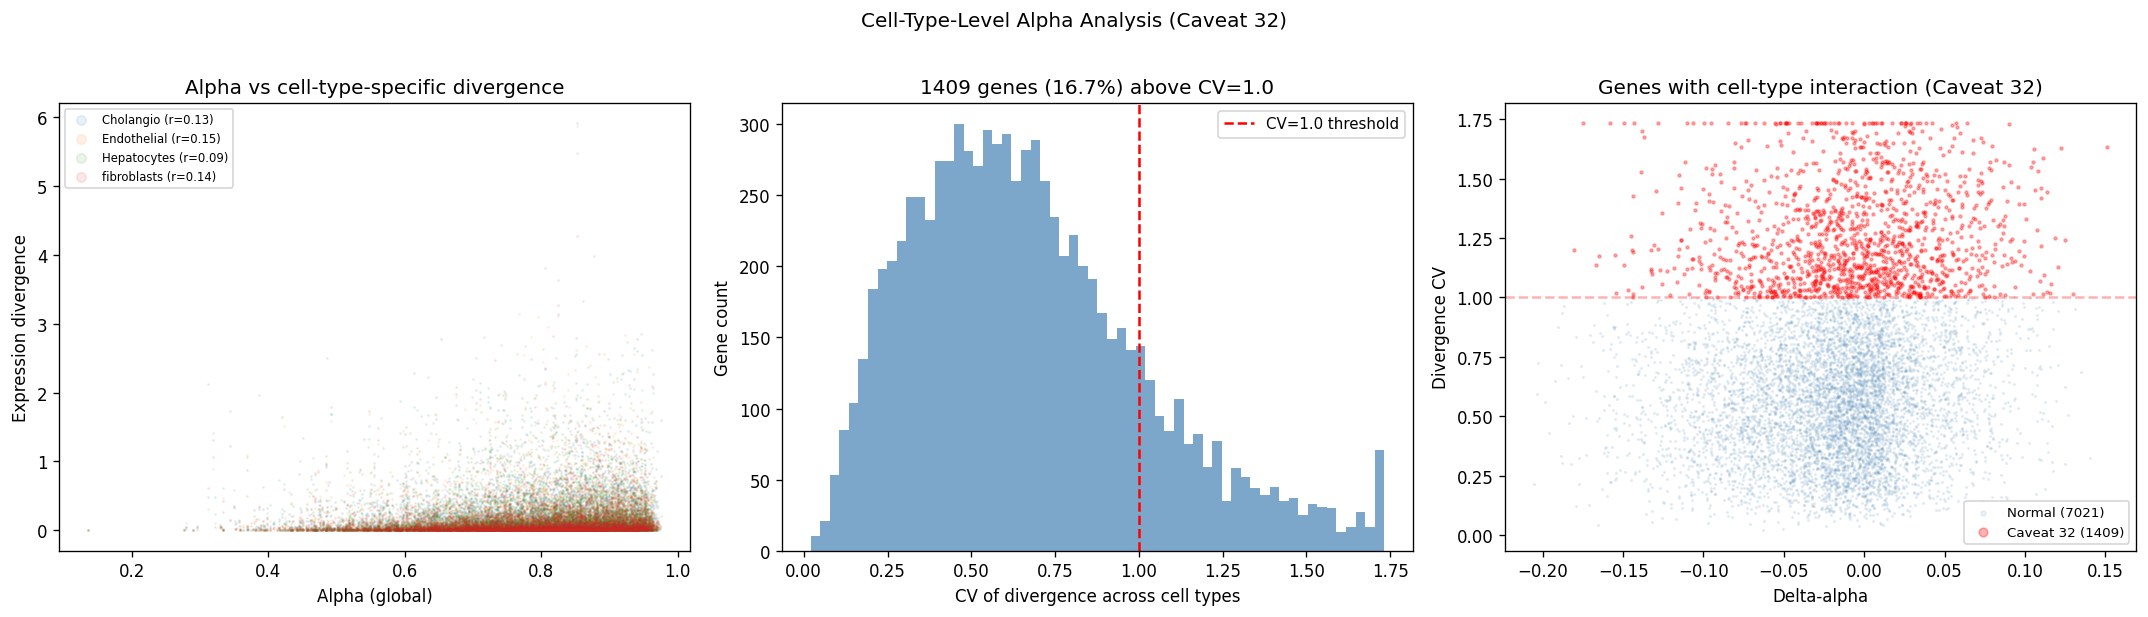

In [23]:
unique_ct = sorted(set(ct_arr))
ct_div = {}
for ct in unique_ct:
    profiles = {}
    for sp in unique_sp:
        mask = (ct_arr == ct) & (species_arr == sp)
        if mask.sum() >= 10:
            profiles[sp] = log_cpm[mask].mean(axis=0)
    if len(profiles) == 2:
        ct_div[ct] = np.abs(profiles[unique_sp[0]] - profiles[unique_sp[1]])

shared_cts = list(ct_div.keys())
if len(shared_cts) >= 2:
    all_divs = np.column_stack([ct_div[ct] for ct in shared_cts])
    div_cv = all_divs.std(axis=1) / (all_divs.mean(axis=1) + 1e-8)
    caveat32_genes = div_cv > 1.0

    fig, axes = plt.subplots(1, 3, figsize=(18, 5))

    ax = axes[0]
    for ct in shared_cts:
        r = spearmanr(alpha, ct_div[ct]).correlation
        ax.scatter(alpha, ct_div[ct], s=0.5, alpha=0.1, label=f'{ct} (r={r:.2f})')
    ax.set_xlabel('Alpha (global)'); ax.set_ylabel('Expression divergence')
    ax.set_title('Alpha vs cell-type-specific divergence')
    ax.legend(fontsize=7, markerscale=8)

    ax = axes[1]
    ax.hist(div_cv, bins=60, color='steelblue', alpha=0.7, edgecolor='none')
    ax.axvline(1.0, color='red', linestyle='--', label='CV=1.0 threshold')
    ax.set_xlabel('CV of divergence across cell types'); ax.set_ylabel('Gene count')
    ax.set_title(f'{caveat32_genes.sum()} genes ({caveat32_genes.mean():.1%}) above CV=1.0')
    ax.legend(fontsize=9)

    ax = axes[2]
    ax.scatter(delta_alpha[~caveat32_genes], div_cv[~caveat32_genes],
              s=1, alpha=0.1, c='steelblue', label=f'Normal ({(~caveat32_genes).sum()})', rasterized=True)
    ax.scatter(delta_alpha[caveat32_genes], div_cv[caveat32_genes],
              s=3, alpha=0.3, c='red', label=f'Caveat 32 ({caveat32_genes.sum()})', rasterized=True)
    ax.set_xlabel('Delta-alpha'); ax.set_ylabel('Divergence CV')
    ax.set_title('Genes with cell-type interaction (Caveat 32)')
    ax.axhline(1.0, color='red', linestyle='--', alpha=0.3)
    ax.legend(fontsize=8, markerscale=3)

    fig.suptitle('Cell-Type-Level Alpha Analysis (Caveat 32)', fontsize=12, y=1.02)
    fig.tight_layout()
    plt.show()
else:
    caveat32_genes = np.zeros(G, dtype=bool)
    div_cv = np.zeros(G)
    print(f'Only {len(shared_cts)} shared cell types — skipping')